# Four-expert MoE: programmatic illumination guidance

Compare three freshly trained masked autoencoders under one paired protocol:

| Arm | Patch processing | Additional objective |
|---|---|---|
| Dense | One dense MLP | None |
| Self-routing MoE | Continuous weighted mixture of four experts | Batch importance balancing |
| Illumination-guided MoE | **Identical four-expert mixture** | Balancing + weak illumination regression/distribution loss |

**No manual illumination annotations, time-of-day classifications, or CE loss are used for training.**
Targets are calculated from each actual augmented image: sRGB → linear luminance → patch median →
log brightness → fixed 5th/95th-percentile calibration fitted on training images only. Four ordered
anchors span 0–1; neighboring anchors receive interpolated soft targets. For level 0.45 the target
is approximately `[0, 0.65, 0.35, 0]`. These are observed-brightness proxies, not physical lux estimates.

The illumination objective combines Huber regression on `sum(router_probability × anchor)` with MSE
to the adjacent-anchor distribution. The distribution term resolves scalar regression's ambiguous
solution of mixing very dark and very bright experts to predict a medium level. Supervision uses
only **visible spatial tokens**, aligned through the decoder's actual masking permutation; CLS is excluded.
All four experts contribute to reconstruction. Their weights sum to one. Expert output projections
are not scaled by four. Small zero-mean expert perturbations break the identical-expert symmetry
that would otherwise initially remove reconstruction gradients from a fully soft router.

Defaults: all 70,000 training stills, three seeds, three passes and 3,282 optimizer updates/model.
All arms have matched sample order, views, masks, optimizer and budgets. Dense has fewer parameters;
the two MoEs are parameter-matched and share the same full-mixture compute. All four expert MLPs
execute per patch, increasing expert compute relative to the older sparse top-1 experiment.
This notebook is self-contained and does not modify or train from the old comparison checkpoints.

**Evaluation:** frozen scene linear probe/kNN, fixed-mask RGB reconstruction, RankMe, common-input
expert CKA, weighted utilization entropy, actual activation frequency, dominant-expert frequency,
and continuous routing mass by illumination/regime/weather/scene. Scene labels fit frozen readouts;
BDD time/weather/scene attributes are used only for post-hoc grouping and clip descriptions.

The tunnel and matched highway day → dusk → night comparisons use the same real videos as the
previous notebook. Continuous per-expert maps and stacked contribution areas are embedded inline.
Videos use frozen models; this is an offline representation/routing study, not an online continual-learning run.

In [1]:
import hashlib
import json
import math
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir()), None)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from inside the cafl4ds repository.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import copy
import shutil
import subprocess
from collections.abc import Iterator
from concurrent.futures import ThreadPoolExecutor
from contextlib import contextmanager
from functools import partial
from time import perf_counter, sleep

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from IPython.display import Markdown, Video
from IPython.display import display as show
from PIL import Image
from scipy.stats import t as student_t
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF

from cafl4ds.jsonio import dumps_valid
from cafl4ds.measurements import linear_cka, rankme
from cafl4ds.models.vit import MoEViTEncoder, TinyViTEncoder, patchify, unpatchify
from cafl4ds.ssl.factory import build_mae
from cafl4ds.ssl.mae import MAELoss

torch.set_num_threads(4)

## Paired settings

The full protocol is the default. Set `resume_run_dir` to this experiment's own folder to resume;
set it to `None` for a fresh run. Small image/update caps are execution checks and are recorded in
the protocol. `illumination_weight` multiplies the combined Huber + distribution-MSE guidance.
Actual targets always come from pixels. The router receives no externally supplied illumination
value at inference; its learned image features predict the mixture weights.

## Dataset and train/support/test split — edit here

All split settings and construction code live in this notebook. Set `bdd_root` to your extracted BDD
directory if automatic local discovery does not find it. The notebook reads images and original BDD
attributes directly; it does not import train/test membership from a previous notebook.

- `split_mode="official"` keeps the full official training split and divides official validation
  clips using **support_fraction:test_fraction**. `train_fraction` is unused in this mode.
- `split_mode="random"` combines official train/val and assigns clips using **train_fraction,
  support_fraction, test_fraction**, which must be positive and sum to 1. For example, 0.8/0.1/0.1.
- Support images fit the linear/kNN readouts; test (`query`) images measure performance.
- Set both evaluation caps to `None` to use the full allocated support/test panels. Fractions apply
  before label filtering, sparse-stratum rounding and caps; actual counts are printed and saved.
- Splits are seeded, stratified and disjoint by **clip ID**. Known video clips are excluded first.
  Training seeds and model arms share the same split when these settings match.

Use a fresh run when changing the split. A warm-start/frozen checkpoint must have trained on disjoint
clips; those notebooks check this explicitly. Saved plots below describe their original completed
runs until you rerun the affected cells with the edited settings.


In [ ]:
# Edit the dataset and split here; no pre-generated CSVs or external configuration are needed.
bdd_root = None  # Set a local path here if automatic dataset discovery cannot find your BDD extraction.
split_mode = "official"  # "official": keep BDD train/val; "random": split the combined image pool.
train_fraction = 0.80  # Used by random mode; official mode retains all official training images.
support_fraction = 0.10  # Labeled support fits the frozen linear/kNN readouts.
test_fraction = 0.10  # Held-out test images are called query in the existing evaluation code.
split_seed = 13  # Use the same value in each notebook for paired comparisons.
split_stratify_by = ("scene", "regime")  # Add "weather", or use () for unstratified splitting.
support_per_scene = 32  # Optional cap AFTER splitting; None uses every eligible support image.
query_per_scene_regime = 64  # Optional cap AFTER splitting; None uses every eligible test image.
extra_excluded_clip_ids = []  # Additional video/sequence IDs to reserve from all still-image partitions.
video_exclusion_manifests = [
    "outputs/bdd-illumination/selected_videos.json",
    "outputs/bdd-day-dusk-night/matched_sources.json",
    "outputs/bdd-video-subset/video_manifest.json",
]

In [ ]:
# Split construction is embedded here; this notebook does not import an external split/config script.
import csv as split_csv
import hashlib as split_hashlib
import json as split_json
import math as split_math
from collections import defaultdict as split_defaultdict


def valid_bdd_root(path: Path) -> bool:
    """Recognize the extracted BDD still-image layout without requiring a previous experiment."""
    return all((path / "images/100k" / name).is_dir() for name in ["train", "val"])


def resolve_bdd_root(configured: str | Path | None) -> Path:
    """Use the notebook's path or discover a local dataset; saved CSVs supply path hints only."""
    if configured is not None:
        candidate = Path(configured).expanduser()
        candidate = candidate if candidate.is_absolute() else repo_root / candidate
        if not valid_bdd_root(candidate):
            raise FileNotFoundError(f"Expected images/100k/train and val below bdd_root={candidate}.")
        return candidate.resolve()
    candidates = [repo_root / name for name in ["data/bdd100k", "data", "bdd100k", "datasets/bdd100k"]]
    for family in ["moe-stills-to-video", "moe-router-comparison", "moe-router-illumination-comparison"]:
        for filename in ["ssl_train.csv", "train.csv"]:
            for manifest in sorted((repo_root / "outputs" / family).glob(f"*/{filename}"), reverse=True):
                with manifest.open(newline="", encoding="utf-8") as stream:
                    first = next(split_csv.DictReader(stream), None)
                if first and first.get("path"):
                    candidates.extend(Path(first["path"]).parents)
    for candidate in candidates:
        if valid_bdd_root(candidate):
            return candidate.resolve()
    raise FileNotFoundError("Set bdd_root in this notebook to your extracted BDD image/label directory.")


def read_bdd_attributes(folder: Path, split: str) -> dict:
    """Read combined or per-image official attributes directly from the configured dataset."""
    combined = folder / "labels" / f"bdd100k_labels_images_{split}.json"
    individual = folder / "labels/100k" / split
    if combined.is_file():
        items = split_json.loads(combined.read_text(encoding="utf-8"))
    elif individual.is_dir():
        items = [split_json.loads(p.read_text(encoding="utf-8")) for p in sorted(individual.glob("*.json"))]
    else:
        raise FileNotFoundError(f"Missing BDD attributes: {combined} or {individual}")
    return {Path(item["name"]).stem: item.get("attributes", {}) for item in items}


def read_bdd_stills(folder: Path) -> list[dict]:
    """Read paths and attributes, without decoding images or loading a saved split."""
    rows = []
    for split in ["train", "val"]:
        attributes = read_bdd_attributes(folder, split)
        for path in sorted((folder / "images/100k" / split).iterdir()):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            attrs = attributes.get(path.stem, {})
            rows.append(
                {
                    "path": str(path),
                    "clip_id": path.stem,
                    "split": split,
                    "scene": attrs.get("scene") or "undefined",
                    "regime": attrs.get("timeofday") or "unknown",
                    "weather": attrs.get("weather") or "undefined",
                }
            )
    return rows


def reserved_video_ids() -> set[str]:
    """Exclude every configured evaluation-video clip before assigning still-image partitions."""
    result = set(extra_excluded_clip_ids)
    for relative in video_exclusion_manifests:
        path = repo_root / relative
        if path.is_file():
            entries = split_json.loads(path.read_text(encoding="utf-8"))
            result.update(str(row["clip_id"]) for row in entries)
    return result


def split_counts(size: int, fractions: list[float]) -> list[int]:
    """Use largest-remainder rounding; retain each partition in sufficiently large strata."""
    expected = [size * fraction for fraction in fractions]
    counts = [split_math.floor(value) for value in expected]
    order = sorted(range(len(counts)), key=lambda i: (expected[i] - counts[i], fractions[i]), reverse=True)
    for index in order[: size - sum(counts)]:
        counts[index] += 1
    if size >= len(counts):
        for index, count in enumerate(counts):
            if count == 0:
                donor = max(range(len(counts)), key=lambda i: counts[i] - expected[i])
                if counts[donor] <= 1:
                    donor = max(range(len(counts)), key=lambda i: counts[i])
                counts[donor] -= 1
                counts[index] += 1
    return counts


def partition_clips(rows: list[dict], names: list[str], fractions: list[float]) -> dict:
    """Assign entire clips using stable seeded ordering within the requested metadata strata."""
    clips = split_defaultdict(list)
    for row in rows:
        clips[str(row["clip_id"])].append(row)
    strata = split_defaultdict(list)
    for clip_id, members in clips.items():
        keys = {tuple(str(row.get(key, "unknown")) for key in split_stratify_by) for row in members}
        if len(keys) != 1:
            raise ValueError(f"Conflicting stratification attributes within clip {clip_id}.")
        strata[next(iter(keys))].append(clip_id)
    partitions = {name: [] for name in names}
    for key in sorted(strata):
        ordered = sorted(
            strata[key], key=lambda clip: split_hashlib.sha256(f"{split_seed}|{clip}".encode()).hexdigest()
        )
        counts = split_counts(len(ordered), fractions)
        start = 0
        for name, count in zip(names, counts, strict=True):
            partitions[name].extend(row for clip in ordered[start : start + count] for row in clips[clip])
            start += count
    return partitions


def cap_split_groups(rows: list[dict], keys: tuple[str, ...], cap: int | None) -> list[dict]:
    """Apply optional per-group evaluation caps after splitting, retaining whole clips."""
    if cap is None:
        return rows
    if not isinstance(cap, int) or isinstance(cap, bool) or cap < 1:
        raise ValueError("Evaluation caps must be positive integers or None.")
    groups = split_defaultdict(dict)
    for row in rows:
        key = tuple(row[name] for name in keys)
        groups[key].setdefault(row["clip_id"], []).append(row)
    return [row for key in sorted(groups) for members in list(groups[key].values())[:cap] for row in members]


def validate_split_settings() -> list[float]:
    """Validate fractions and stratification before reading any dataset metadata."""
    fractions = [train_fraction, support_fraction, test_fraction]
    if any(not split_math.isfinite(value) or value <= 0 for value in fractions):
        raise ValueError("train_fraction, support_fraction and test_fraction must be finite and positive.")
    if not split_math.isclose(sum(fractions), 1.0, abs_tol=1e-9):
        raise ValueError("train_fraction + support_fraction + test_fraction must equal 1.")
    if split_mode not in {"official", "random"}:
        raise ValueError('split_mode must be "official" or "random".')
    if not set(split_stratify_by).issubset({"scene", "regime", "weather"}):
        raise ValueError("Stratification may use scene, regime, and/or weather; () gives unstratified splitting.")
    return fractions


def build_notebook_splits(extra_video_ids: set[str] | None = None) -> tuple[dict, list[str], dict]:
    """Build train/support/test directly from BDD metadata using only this notebook's settings."""
    fractions = validate_split_settings()
    excluded = reserved_video_ids() | set(extra_video_ids or ())
    all_rows = read_bdd_stills(dataset_root)
    rows = [row for row in all_rows if row["clip_id"] not in excluded]
    if split_mode == "official":
        train = [row for row in rows if row["split"] == "train"]
        evaluation = [row for row in rows if row["split"] == "val"]
        ratio = support_fraction / (support_fraction + test_fraction)
        parts = {"train": train, **partition_clips(evaluation, ["support", "query"], [ratio, 1 - ratio])}
    else:
        parts = partition_clips(rows, ["train", "support", "query"], fractions)
    for name in ["support", "query"]:
        parts[name] = [
            row
            for row in parts[name]
            if row["scene"] not in {"undefined", ""} and row["regime"] in {"daytime", "dawn/dusk", "night"}
        ]
    parts["support"] = cap_split_groups(parts["support"], ("scene",), support_per_scene)
    parts["query"] = cap_split_groups(parts["query"], ("scene", "regime"), query_per_scene_regime)
    scenes = sorted({row["scene"] for row in parts["support"]} & {row["scene"] for row in parts["query"]})
    for name in ["support", "query"]:
        parts[name] = [row for row in parts[name] if row["scene"] in scenes]
    if any(not part for part in parts.values()) or len(scenes) < 2:
        raise ValueError("Split is empty or has fewer than two shared scene classes; increase data/fractions or caps.")
    ids = {name: {row["clip_id"] for row in part} for name, part in parts.items()}
    if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
        raise ValueError("Clip overlap between train/support/test; check duplicate BDD source identifiers.")
    contract = {
        "version": "notebook-bdd-clip-split-v1",
        "dataset_root": str(dataset_root),
        "mode": split_mode,
        "train_fraction": train_fraction,
        "support_fraction": support_fraction,
        "test_fraction": test_fraction,
        "seed": split_seed,
        "stratify_by": list(split_stratify_by),
        "support_per_scene": support_per_scene,
        "query_per_scene_regime": query_per_scene_regime,
        "excluded_video_ids_sha256": split_hashlib.sha256("\n".join(sorted(excluded)).encode()).hexdigest(),
    }
    print("Split built in this notebook:", {name: len(part) for name, part in parts.items()})
    if split_mode == "official":
        print(
            "Official train retained; official val divided by support_fraction:test_fraction; train_fraction is unused."
        )
    print("Fractions apply before unknown-label filtering, sparse-stratum rounding and evaluation caps.")
    return parts, scenes, contract


def guard_notebook_split(folder: Path, contract: dict) -> None:
    """Reject edited split settings before overwriting manifests in an existing run."""
    path = folder / "split_settings.json"
    if path.exists() and split_json.loads(path.read_text()) != contract:
        raise ValueError("Split settings changed. Choose a fresh run directory before regenerating its partitions.")
    path.write_text(split_json.dumps(contract, indent=2), encoding="utf-8")


def find_stills_checkpoint(configured: str | Path | None) -> Path:
    """Find an existing model for notebooks that explicitly perform warm-start or frozen evaluation."""
    candidates = (
        [Path(configured).expanduser()]
        if configured
        else sorted((repo_root / "outputs/moe-stills-to-video").glob("*/checkpoint.pt"), reverse=True)
    )
    for candidate in candidates:
        resolved = candidate if candidate.is_absolute() else repo_root / candidate
        folder = resolved.parent if resolved.is_file() else resolved
        if all((folder / name).is_file() for name in ["checkpoint.pt", "config.json", "ssl_train.csv"]):
            return folder.resolve()
    raise FileNotFoundError("Set checkpoint_run_dir in this notebook to a trained stills-to-video model run.")


def check_pretrained_split(folder: Path, parts: dict) -> None:
    """A warm-start/frozen checkpoint must never have pretrained on the new evaluation clips."""
    with (folder / "ssl_train.csv").open(newline="", encoding="utf-8") as stream:
        trained = {row["clip_id"] for row in split_csv.DictReader(stream)}
    overlap = trained & {row["clip_id"] for name in ["support", "query"] for row in parts[name]}
    overlap |= trained & reserved_video_ids()
    if overlap:
        raise ValueError(
            f"The selected checkpoint trained on {len(overlap)} new support/test clips. "
            "Train moe_stills_to_video with these same split settings first, then select that checkpoint_run_dir."
        )


dataset_root = resolve_bdd_root(bdd_root)

In [ ]:
source_run = dataset_root
seeds = [13, 42, 101]
epochs = 3
batch_size = 64
learning_rate = 1e-4
weight_decay = 1e-4
balance_weight = 0.01
illumination_weight = 0.01
distribution_weight = 1.0
huber_beta = 0.1
expert_perturbation = 0.02
gradient_clip = 1.0
training_log_every_steps = 25
evaluate_every_steps = 250
gradient_every_steps = 250
checkpoint_every_steps = 500
max_train_images = None
max_query_images = None
max_steps_per_epoch = None
cka_images = 512
reconstruction_masks = 3
knn_k = 20
cache_workers = 4
prefer_cuda = True
resume_run_dir = None
calibration_percentiles = [5.0, 95.0]
luminance_floor = 1e-4
video_seed = seeds[0]
video_fps = 10.0
video_seconds_per_regime = 15.0
tunnel_max_seconds = None
export_comparison_videos = True

img_size, patch_size = 64, 8
embed_dim, depth, num_heads = 96, 4, 3
moe_blocks = (2, 3)
analysis_block = max(moe_blocks)
num_experts, top_k = 4, 4
router_noise_std = 0.0
mask_ratio = 0.75
regime_names = ["daytime", "dawn/dusk", "night"]  # Post-hoc evaluation groups only.
regime_to_id = {name: i for i, name in enumerate(regime_names)}
device = torch.device("cuda" if prefer_cuda and torch.cuda.is_available() else "cpu")
arms = [
    {"name": "dense", "kind": "dense", "illumination_weight": 0.0},
    {"name": "self_moe", "kind": "moe", "illumination_weight": 0.0},
    {"name": "illum_moe", "kind": "moe", "illumination_weight": illumination_weight},
]
arm_names = [spec["name"] for spec in arms]
arm_labels = {"dense": "Dense baseline", "self_moe": "Four-expert self-routing", "illum_moe": "Illumination-guided MoE"}
arm_colors = {"dense": "#667085", "self_moe": "#2474b7", "illum_moe": "#d55e00"}
expert_colors = ["#4c78a8", "#f58518", "#54a24b", "#e45756"]
run_dir = (
    Path(resume_run_dir)
    if resume_run_dir
    else repo_root
    / "outputs/moe-router-illumination-comparison"
    / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
run_dir.mkdir(parents=True, exist_ok=True)
if not seeds or len(set(seeds)) != len(seeds) or video_seed not in seeds:
    raise ValueError("Use unique training seeds and a video seed included in them.")
if (
    min(
        epochs,
        batch_size,
        cache_workers,
        training_log_every_steps,
        evaluate_every_steps,
        checkpoint_every_steps,
        gradient_every_steps,
    )
    < 1
):
    raise ValueError("Budgets and measurement intervals must be positive.")
if illumination_weight <= 0 or distribution_weight <= 0 or expert_perturbation <= 0 or huber_beta <= 0:
    raise ValueError("Use positive guidance, distribution, symmetry-breaking and Huber parameters.")
print(f"{len(arms) * len(seeds)} fresh paired models; four-way soft patch mixtures; device={device}; output={run_dir}")

In [4]:
def preprocess_rgb(rgb: np.ndarray) -> torch.Tensor:
    """RGB uint8 → float [0,1], resized with antialiasing to the model's square input."""
    tensor = TF.to_tensor(rgb)
    return TF.resize(tensor, [img_size, img_size], antialias=True)

In [5]:
@torch.no_grad()
def raw_patch_illumination(images: torch.Tensor) -> torch.Tensor:
    """Log median linear-light luminance for each row-major image patch; no annotation inputs."""
    rgb = images.detach().float().clamp(0, 1)
    linear = torch.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055).pow(2.4))
    luminance = 0.2126 * linear[:, 0:1] + 0.7152 * linear[:, 1:2] + 0.0722 * linear[:, 2:3]
    median = patchify(luminance, patch_size).median(-1).values
    return median.clamp_min(luminance_floor).log()


@torch.no_grad()
def patch_illumination(images: torch.Tensor) -> torch.Tensor:
    """Apply the fixed training-only calibration to observed brightness in the actual view."""
    raw = raw_patch_illumination(images)
    return ((raw - normalizer["low"]) / (normalizer["high"] - normalizer["low"])).clamp(0, 1)


def soft_illumination_targets(levels: torch.Tensor) -> torch.Tensor:
    """Linearly interpolate between adjacent ordered anchors; targets sum to one and retain the level."""
    position = levels.detach().clamp(0, 1) * (num_experts - 1)
    lower = position.floor().long().clamp(max=num_experts - 2)
    fraction = position - lower
    targets = torch.zeros(*levels.shape, num_experts, device=levels.device, dtype=levels.dtype)
    targets.scatter_(-1, lower.unsqueeze(-1), (1 - fraction).unsqueeze(-1))
    targets.scatter_add_(-1, (lower + 1).unsqueeze(-1), fraction.unsqueeze(-1))
    return targets


@contextmanager
def capture_training_routing(model: torch.nn.Module) -> Iterator[dict[str, Any]]:
    """Capture actual differentiable mixture probabilities and the decoder's real MAE restoration permutation."""
    captured = {"probabilities": {}}

    def capture_block(block: int, _module: torch.nn.Module, _args: tuple, output: Any) -> None:  # noqa: ANN401
        """Retain the same four-way weights used in the reconstruction forward graph."""
        captured["probabilities"][block] = output.routing_probs

    def capture_restore(_module: torch.nn.Module, inputs: tuple) -> None:
        """Read actual kept-token count and shuffle inversion; never infer patch identity from token position."""
        captured["kept"] = inputs[0].shape[1] - 1
        captured["ids_restore"] = inputs[1]

    handles = [model.encoder.blocks[b].mlp.register_forward_hook(partial(capture_block, b)) for b in moe_blocks]
    handles.append(model.decoder.register_forward_pre_hook(capture_restore))
    try:
        yield captured
    finally:
        for handle in handles:
            handle.remove()


def illumination_losses(captured: dict[str, Any], levels: torch.Tensor) -> dict[str, torch.Tensor]:
    """Supervise only visible spatial tokens, matched through the actual MAE permutation; exclude CLS."""
    kept_indices = captured["ids_restore"].argsort(1)[:, : captured["kept"]]
    visible_levels = levels.gather(1, kept_indices)
    targets = soft_illumination_targets(visible_levels)
    centers = torch.linspace(0, 1, num_experts, device=levels.device, dtype=levels.dtype)
    regression, distributions, errors = [], [], []
    for probabilities in captured["probabilities"].values():
        spatial = probabilities[:, 1:, :]
        if spatial.shape != targets.shape:
            raise ValueError("Visible routing and illumination targets have different token identities/shapes.")
        predicted = (spatial * centers).sum(-1)
        regression.append(F.smooth_l1_loss(predicted, visible_levels, beta=huber_beta))
        distributions.append(F.mse_loss(spatial, targets))
        errors.append((predicted - visible_levels).abs().mean())
    regression_loss, distribution_loss = torch.stack(regression).mean(), torch.stack(distributions).mean()
    return {
        "total": regression_loss + distribution_weight * distribution_loss,
        "regression": regression_loss,
        "distribution": distribution_loss,
        "level_mae": torch.stack(errors).mean(),
    }

In [ ]:
split_parts, scene_names, split_contract = build_notebook_splits(set())
guard_notebook_split(run_dir, split_contract)
frames = {name: pd.DataFrame(rows) for name, rows in split_parts.items()}
for name, cap in [("train", max_train_images), ("query", max_query_images)]:
    if cap is not None:
        frames[name] = frames[name].sample(n=min(cap, len(frames[name])), random_state=0).reset_index(drop=True)
ids = {name: set(frame["clip_id"]) for name, frame in frames.items()}
if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
    raise ValueError("Training, support and query clips must be disjoint.")
scene_to_id = {name: i for i, name in enumerate(scene_names)}
records = {name: frame.to_dict("records") for name, frame in frames.items()}
steps_per_epoch = math.ceil(len(records["train"]) / batch_size)
if max_steps_per_epoch is not None:
    steps_per_epoch = min(steps_per_epoch, max_steps_per_epoch)
total_updates = epochs * steps_per_epoch
if steps_per_epoch < 1:
    raise ValueError("Empty training update budget.")
for name, frame in frames.items():
    frame.to_csv(run_dir / f"{name}.csv", index=False)
protocol = {
    "split_settings": split_contract,
    "source_run": str(source_run),
    "seeds": seeds,
    "epochs": epochs,
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "weight_decay": weight_decay,
    "balance_weight": balance_weight,
    "gradient_clip": gradient_clip,
    "illumination_weight": illumination_weight,
    "distribution_weight": distribution_weight,
    "huber_beta": huber_beta,
    "expert_perturbation": expert_perturbation,
    "calibration_percentiles": calibration_percentiles,
    "luminance_floor": luminance_floor,
    "routing": "full four-way soft spatial mixture",
    "arms": arms,
    "total_updates": total_updates,
    "img_size": img_size,
    "patch_size": patch_size,
    "embed_dim": embed_dim,
    "depth": depth,
    "num_heads": num_heads,
    "moe_blocks": list(moe_blocks),
    "num_experts": num_experts,
    "top_k": top_k,
    "router_noise_std": router_noise_std,
    "mask_ratio": mask_ratio,
    "max_train_images": max_train_images,
    "max_query_images": max_query_images,
    "max_steps_per_epoch": max_steps_per_epoch,
    "cka_images": cka_images,
    "reconstruction_masks": reconstruction_masks,
    "knn_k": knn_k,
    "evaluation_interval": evaluate_every_steps,
    "gradient_interval": gradient_every_steps,
    "training_log_interval": training_log_every_steps,
    "checkpoint_interval": checkpoint_every_steps,
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "device": str(device),
    "data_ids": {
        name: hashlib.sha256("\n".join(frame["clip_id"]).encode()).hexdigest() for name, frame in frames.items()
    },
}
fixed_masks = torch.rand(
    reconstruction_masks, (img_size // patch_size) ** 2, generator=torch.Generator().manual_seed(7701)
)
torch.save(fixed_masks, run_dir / "evaluation_masks.pt")

# Cache the exact float32 preprocessing once. This is not a quantized/resized JPEG cache.
cache_paths = list(dict.fromkeys(row["path"] for part in records.values() for row in part))
cache_contract = {
    "version": "rgb-float32-antialiased-resize-v1",
    "shape": [len(cache_paths), 3, img_size, img_size],
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "images": [
        {"path": path, "size": Path(path).stat().st_size, "mtime_ns": Path(path).stat().st_mtime_ns}
        for path in cache_paths
    ],
}
cache_key = hashlib.sha256(dumps_valid(cache_contract).encode()).hexdigest()[:16]
shared_cache = repo_root / "outputs/moe-router-ce-ablation/input_cache" / cache_key
cache_dir = (
    shared_cache
    if (shared_cache / "manifest.json").exists()
    else repo_root / "outputs/moe-router-illumination-comparison/input_cache" / cache_key
)
cache_dir.mkdir(parents=True, exist_ok=True)
cache_path = cache_dir / "images.npy"
cache_manifest_path = cache_dir / "manifest.json"
cache_index = {path: i for i, path in enumerate(cache_paths)}


def decode_cache_image(path: str) -> np.ndarray:
    """Run exactly the original image decoder and float32 preprocessing, without augmentation."""
    with Image.open(path) as image:
        rgb = np.array(image.convert("RGB"))
    return preprocess_rgb(rgb).numpy()


if cache_manifest_path.exists():
    cache_manifest = json.loads(cache_manifest_path.read_text(encoding="utf-8"))
    if cache_manifest["contract"] != cache_contract or not cache_path.exists():
        raise ValueError("Input-cache metadata does not match the current image panel.")
    print(f"Reusing exact preprocessing cache: {cache_dir}")
else:
    required_bytes = len(cache_paths) * 3 * img_size * img_size * 4
    if shutil.disk_usage(cache_dir).free < required_bytes * 1.1:
        raise OSError("Not enough disk space for the exact float32 preprocessing cache.")
    cache_threads = torch.get_num_threads()
    temporary = cache_dir / "images.partial.npy"
    try:
        torch.set_num_threads(1)
        cache_writer = np.lib.format.open_memmap(
            temporary, mode="w+", dtype=np.float32, shape=tuple(cache_contract["shape"])
        )
        with ThreadPoolExecutor(max_workers=cache_workers) as pool:
            # Small chunks bound decoded-image buffers while preserving deterministic path order.
            for cache_start in range(0, len(cache_paths), 256):
                for cache_offset, cache_image in enumerate(
                    pool.map(decode_cache_image, cache_paths[cache_start : cache_start + 256])
                ):
                    cache_writer[cache_start + cache_offset] = cache_image
                if cache_start % 2048 == 0:
                    print(
                        f"Exact input cache: {min(cache_start + 256, len(cache_paths))}/{len(cache_paths)} images",
                        flush=True,
                    )
        cache_writer.flush()
        del cache_writer
        temporary.replace(cache_path)
    finally:
        torch.set_num_threads(cache_threads)
    cache_manifest = {"contract": cache_contract, "bytes": cache_path.stat().st_size}
    cache_manifest_path.write_text(dumps_valid(cache_manifest), encoding="utf-8")
image_cache = np.load(cache_path, mmap_mode="r")
if image_cache.dtype != np.float32 or list(image_cache.shape) != cache_contract["shape"]:
    raise ValueError("Cached tensor shape/dtype mismatch.")
for cache_i in np.linspace(0, len(cache_paths) - 1, min(12, len(cache_paths)), dtype=int):
    if not np.array_equal(image_cache[cache_i], decode_cache_image(cache_paths[cache_i])):
        raise ValueError("Cached preprocessing differs from direct preprocessing.")
(run_dir / "input_cache.json").write_text(
    dumps_valid(
        {
            "path": str(cache_path),
            "key": cache_key,
            "validated_pixels": "exact float32 equality on a fixed spread of images",
        }
    ),
    encoding="utf-8",
)
print(
    f"Paired budget: {total_updates} updates/model; "
    f"panel sizes: { {name: len(part) for name, part in records.items()} }"
)


class ComparisonDataset(Dataset):
    """Read the exact cached input tensor while keeping scene and regime targets separate."""

    def __init__(self, rows: list[dict[str, Any]]) -> None:
        """Store the ordered panel metadata."""
        self.rows = rows

    def __len__(self) -> int:
        """Count images in this fixed panel."""
        return len(self.rows)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int, int]:
        """Copy one cached image with optional evaluation metadata; training ignores the labels."""
        row = self.rows[index]
        image = torch.from_numpy(np.array(image_cache[cache_index[row["path"]]], copy=True))
        return image, scene_to_id.get(row.get("scene"), -100), regime_to_id.get(row.get("regime"), -100)


def loader(rows: list[dict[str, Any]], seed: int, epoch: int = 0, shuffle: bool = False) -> DataLoader:
    """Replay the same sample order for each paired arm, independent of previous RNG consumption."""
    return DataLoader(
        ComparisonDataset(rows),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed + epoch * 1009),
        pin_memory=device.type == "cuda",
    )

## Calculate illumination targets from training pixels

Only training images fit the fixed calibration. Support/query frames and videos do not affect the
normalizer, anchors or training loss. The same normalization is retained across frames so a genuine
brightness change is not erased by per-frame normalization. Targets are recomputed after augmentation
and before masking. The preview is generated from pixels, without time-of-day or scene annotations.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.017083777..1.0000002].


Training-only illumination calibration: {'low': -6.5189333200454715, 'high': -0.5540148973464969, 'training_images': 70000, 'training_patches': 4480000, 'centers': [0.0, 0.3333333333333333, 0.6666666666666666, 1.0]}


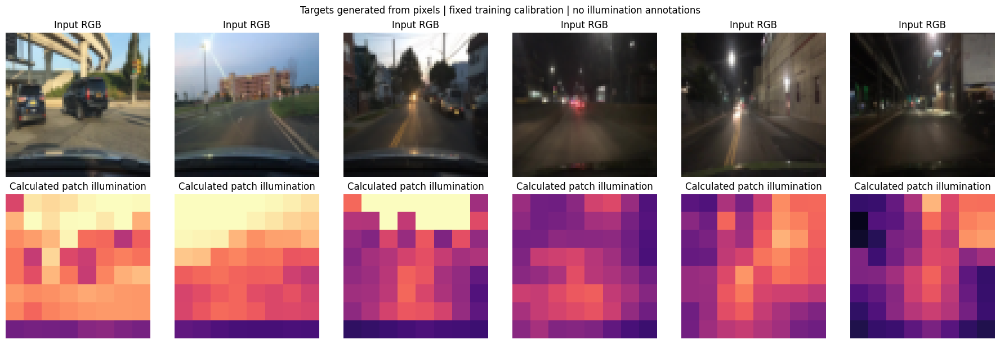

In [7]:
calibration_contract = {
    "version": "linear-srgb-log-median-patch-v1",
    "training_ids": protocol["data_ids"]["train"],
    "input_cache_key": cache_key,
    "patch_size": patch_size,
    "percentiles": calibration_percentiles,
    "luminance_floor": luminance_floor,
    "images": len(records["train"]),
}
normalizer_path = run_dir / "illumination_calibration.json"
if normalizer_path.exists():
    saved_normalizer = json.loads(normalizer_path.read_text())
    if saved_normalizer["contract"] != calibration_contract:
        raise ValueError("Calibration metadata differs; use a fresh run directory.")
    normalizer = saved_normalizer["normalizer"]
else:
    calibration_values = []
    for images, _unused_scenes, _unused_regimes in loader(records["train"], seeds[0]):
        calibration_values.append(raw_patch_illumination(images.to(device)).cpu().numpy().reshape(-1))
    calibration_values = np.concatenate(calibration_values)
    low, high = np.percentile(calibration_values, calibration_percentiles)
    if not np.isfinite([low, high]).all() or high - low < 1e-6:
        raise ValueError("Training brightness range is degenerate.")
    normalizer = {
        "low": float(low),
        "high": float(high),
        "training_images": len(records["train"]),
        "training_patches": int(len(calibration_values)),
        "centers": np.linspace(0, 1, num_experts).tolist(),
    }
    normalizer_path.write_text(
        dumps_valid({"contract": calibration_contract, "normalizer": normalizer}), encoding="utf-8"
    )
    del calibration_values
protocol["illumination_calibration"] = normalizer
protocol_hash = hashlib.sha256(dumps_valid(protocol).encode()).hexdigest()
protocol_path = run_dir / "protocol.json"
if protocol_path.exists() and json.loads(protocol_path.read_text())["protocol_hash"] != protocol_hash:
    raise ValueError("Saved run protocol differs; use a fresh output folder.")
protocol_path.write_text(dumps_valid({"protocol_hash": protocol_hash, "protocol": protocol}), encoding="utf-8")
print(f"Training-only illumination calibration: {normalizer}")
preview_rows = records["train"][: min(6, len(records["train"]))]
preview_images = next(iter(loader(preview_rows, seeds[0])))[0]
preview_levels = patch_illumination(preview_images)
fig, axes = plt.subplots(
    2, len(preview_images), figsize=(3 * len(preview_images), 6), squeeze=False, constrained_layout=True
)
for i, image in enumerate(preview_images):
    axes[0, i].imshow(image.permute(1, 2, 0))
    axes[1, i].imshow(preview_levels[i].reshape(img_size // patch_size, -1), vmin=0, vmax=1, cmap="magma")
    axes[0, i].set_title("Input RGB")
    axes[1, i].set_title("Calculated patch illumination")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Targets generated from pixels | fixed training calibration | no illumination annotations")
fig.savefig(run_dir / "calculated_illumination_preview.png", dpi=150)
show(fig)
plt.close(fig)

In [8]:
def initialize_arms(seed: int) -> dict[str, torch.nn.Module]:
    """Share dense weights and clone two matched full-mixture MoEs with tiny zero-mean expert perturbations."""
    torch.manual_seed(seed)
    encoder_config = {
        "img_size": img_size,
        "patch_size": patch_size,
        "embed_dim": embed_dim,
        "depth": depth,
        "num_heads": num_heads,
        "mlp_ratio": 2.0,
    }
    mae_config = {
        "mask_ratio": mask_ratio,
        "decoder_dim": 64,
        "decoder_depth": 2,
        "decoder_heads": 4,
        "norm_pix_loss": False,
    }
    dense = build_mae(TinyViTEncoder(**encoder_config), aux_weight=0.0, **mae_config)
    moe = build_mae(
        MoEViTEncoder(
            **encoder_config,
            num_experts=num_experts,
            top_k=top_k,
            moe_blocks=moe_blocks,
            routing_level="token",
            router_noise_std=router_noise_std,
        ),
        aux_weight=balance_weight,
        **mae_config,
    )
    destination, source = moe.state_dict(), dense.state_dict()
    for name in destination:
        if name in source and source[name].shape == destination[name].shape:
            destination[name] = source[name].clone()
    for block in moe_blocks:
        for suffix, value in dense.encoder.blocks[block].mlp.state_dict().items():
            if suffix == "fc2.weight":
                noise = torch.randn(num_experts, *value.shape) * value.std() * expert_perturbation
                noise -= noise.mean(0, keepdim=True)
            else:
                noise = torch.zeros(num_experts, *value.shape)
            for expert in range(num_experts):
                # Full soft mixtures sum to one: do not multiply output projections by the expert count.
                destination[f"encoder.blocks.{block}.mlp.experts.{expert}.{suffix}"] = value.clone() + noise[expert]
    moe.load_state_dict(destination, strict=True)
    for block in moe_blocks:
        torch.nn.init.normal_(moe.encoder.blocks[block].mlp.router.weight, std=0.001)
        torch.nn.init.zeros_(moe.encoder.blocks[block].mlp.router.bias)
    return {"dense": dense, "self_moe": moe, "illum_moe": copy.deepcopy(moe)}

In [9]:
@torch.no_grad()
def masked_mse(model: torch.nn.Module, images: torch.Tensor) -> torch.Tensor:
    """Use identical unaugmented full-frame RGB targets and fixed mask templates across arms."""
    target = patchify(images, patch_size)
    values = []
    for mask in fixed_masks:
        result = model.encoder.forward_with_aux(
            images, mask_ratio=mask_ratio, mask_noise=mask[None].expand(len(images), -1).to(images.device)
        )
        prediction = model.decoder(result.tokens, result.ids_restore)
        error = (prediction - target).square().mean(-1)
        values.append((error * result.mask).sum(-1) / result.mask.sum(-1).clamp_min(1))
    return torch.stack(values).mean(0)


@torch.no_grad()
def embeddings(
    model: torch.nn.Module, rows: list[dict[str, Any]], seed: int
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Encode rows in fixed order, without fitting or updating the encoder."""
    model.eval()
    features, labels, errors = [], [], []
    for cpu_images, scenes, _regimes in loader(rows, seed):
        images = cpu_images.to(device)
        features.append(model.encode(images).cpu().numpy())
        labels.append(scenes.numpy())
        errors.append(masked_mse(model, images).cpu().numpy())
    return np.concatenate(features), np.concatenate(labels), np.concatenate(errors)


def external_evaluation(
    model: torch.nn.Module, arm: str, seed: int, stage: str
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    """Fit only frozen-feature readouts; score the exact same query clips in every arm."""
    support, y_support, _ = embeddings(model, records["support"], seed)
    query, y_query, errors = embeddings(model, records["query"], seed)
    linear = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=seed))
    knn = KNeighborsClassifier(n_neighbors=min(knn_k, len(support)), metric="cosine", weights="distance")
    linear.fit(support, y_support)
    knn.fit(support, y_support)
    guesses = {"linear": linear.predict(query), "knn": knn.predict(query)}
    rows = []
    regimes = np.array([row["regime"] for row in records["query"]])
    for regime in ["all", *regime_names]:
        selected = np.arange(len(query)) if regime == "all" else np.flatnonzero(regimes == regime)
        if not len(selected):
            continue
        features = query[selected]
        effective_rank = rankme(torch.tensor(features))
        row = {
            "arm": arm,
            "seed": seed,
            "stage": stage,
            "regime": regime,
            "images": len(selected),
            "masked_rgb_mse": float(errors[selected].mean()),
            "rankme": effective_rank,
            "rankme_normalized": effective_rank / min(features.shape),
        }
        for name, prediction in guesses.items():
            row[f"{name}_accuracy"] = accuracy_score(y_query[selected], prediction[selected])
            row[f"{name}_macro_f1"] = f1_score(
                y_query[selected], prediction[selected], average="macro", zero_division=0
            )
        rows.append(row)
    return rows, {"linear": linear, "knn": knn, "query_features": query}


def safe_cka(x: np.ndarray, y: np.ndarray) -> float:
    """Treat constant/fewer-than-two-sample representations as undefined, not evidence of diversity."""
    if len(x) < 2 or np.square(x - x.mean(0)).sum() < 1e-12 or np.square(y - y.mean(0)).sum() < 1e-12:
        return float("nan")
    return linear_cka(torch.tensor(x, dtype=torch.float64), torch.tensor(y, dtype=torch.float64))


@torch.no_grad()
def internal_evaluation(model: torch.nn.Module, arm: str, seed: int) -> dict[str, Any]:
    """Compare common-input expert representations and real mixture weights at the final MoE block."""
    model.eval()
    rows = records["query"][:cka_images]
    layer = model.encoder.blocks[analysis_block].mlp
    captured = {}

    def save_input(_module: torch.nn.Module, args: tuple) -> None:
        """Read the normalized hidden-token inputs shared by counterfactual expert probes."""
        captured["tokens"] = args[0].detach()

    handle = layer.register_forward_pre_hook(save_input)
    representations = [[] for _ in range(1 if arm == "dense" else num_experts)]
    probabilities, dominant_counts = [], []
    try:
        for cpu_images, _unused_scenes, _unused_regimes in loader(rows, seed):
            images = cpu_images.to(device)
            if arm == "dense":
                model.encoder(images)
            else:
                routing = model.encoder.routing(images)[analysis_block][:, 1:, :]
                probabilities.append(routing.mean(1).cpu().numpy())
                dominant_counts.append(F.one_hot(routing.argmax(-1), num_experts).sum(1).cpu().numpy())
            tokens = captured.pop("tokens")[:, 1:, :]
            if arm == "dense":
                representations[0].append(layer(tokens).mean(1).cpu().numpy())
            else:
                for i, expert in enumerate(layer.experts):
                    representations[i].append(expert(tokens).mean(1).cpu().numpy())
    finally:
        handle.remove()
    result = {
        "representations": [np.concatenate(v) for v in representations],
        "clip_ids": [r["clip_id"] for r in rows],
        "utilization": [],
        "entropy": [],
    }
    if arm == "dense":
        return result
    mass, counts = np.concatenate(probabilities), np.concatenate(dominant_counts)
    regimes = np.array([r["regime"] for r in rows])
    for regime in ["all", *regime_names]:
        selected = np.arange(len(rows)) if regime == "all" else np.flatnonzero(regimes == regime)
        if not len(selected):
            continue
        share = mass[selected].mean(0)
        entropy = float(-(share * np.log(share.clip(1e-12))).sum())
        result["entropy"].append(
            {
                "arm": arm,
                "seed": seed,
                "block": analysis_block,
                "regime": regime,
                "images": len(selected),
                "entropy_nats": entropy,
                "entropy_normalized": entropy / np.log(num_experts),
                "basis": "mean mixture probability",
            }
        )
        dominant = counts[selected].sum(0)
        for expert in range(num_experts):
            result["utilization"].append(
                {
                    "arm": arm,
                    "seed": seed,
                    "block": analysis_block,
                    "regime": regime,
                    "expert": expert,
                    "mean_probability": float(share[expert]),
                    "dominant_frequency": float(dominant[expert] / dominant.sum()),
                    "dominant_tokens": int(dominant[expert]),
                    "total_spatial_tokens": int(dominant.sum()),
                    "token_activation_frequency": 1.0,
                    "image_activation_frequency": 1.0,
                }
            )
    return result

In [10]:
def atomic_replace(source: Path, target: Path) -> None:
    """Keep atomic checkpoints while tolerating short Windows scanner locks on recently written files."""
    for attempt in range(8):
        try:
            source.replace(target)
            return
        except PermissionError:
            if attempt == 7:
                raise
            sleep(0.05 * 2 ** min(attempt, 4))


def guidance_coefficient(spec: dict[str, Any], _update: int) -> float:
    """Use a fixed, recorded illumination-guidance coefficient; no regime labels or CE schedule."""
    return float(spec["illumination_weight"])


def append_rows(path: Path, rows: list[dict[str, Any]]) -> None:
    """Append observations using a stable header, without writing partial JSON reports."""
    if rows:
        pd.DataFrame(rows).to_csv(path, mode="a", header=not path.exists(), index=False)


def write_status(**values: object) -> None:
    """Atomically publish progress in this experiment's own output folder."""
    status = {
        "run_dir": str(run_dir),
        "models": len(arms) * len(seeds),
        "updates_per_model": total_updates,
        "completed_models": globals().get("completed_models", 0),
        "utc": datetime.now(timezone.utc).isoformat(),
        **values,
    }
    temporary = run_dir / "status.partial.json"
    temporary.write_text(dumps_valid(status), encoding="utf-8")
    atomic_replace(temporary, run_dir / "status.json")


@contextmanager
def training_readouts(model: torch.nn.Module) -> Iterator[dict[str, float]]:
    """Observe the actual noisy training gate and weighted MLP output, without another forward or RNG draw."""
    values = {}

    def capture(_module: torch.nn.Module, inputs: tuple, output: Any) -> None:  # noqa: ANN401
        """Read detached statistics while leaving the training graph untouched."""
        features = output.features if hasattr(output, "features") else output
        values["mlp_output_rms"] = float(features[:, 1:].detach().square().mean().sqrt())
        values["mlp_input_rms"] = float(inputs[0][:, 1:].detach().square().mean().sqrt())
        probabilities = getattr(output, "routing_probs", None)
        values["selected_gate_mean"] = (
            float(probabilities[:, 1:].detach().max(-1).values.mean()) if probabilities is not None else float("nan")
        )

    handle = model.encoder.blocks[analysis_block].mlp.register_forward_hook(capture)
    try:
        yield values
    finally:
        handle.remove()


def gradient_diagnostics(
    model: torch.nn.Module,
    losses: MAELoss,
    guidance: torch.Tensor,
    coefficient: float,
    spec: dict[str, Any],
    seed: int,
    update: int,
) -> list[dict[str, Any]]:  # noqa: ANN401
    """Measure task/guidance/balance gradients on the same training graph; never accumulate parameter .grad buffers."""
    if spec["kind"] == "dense":
        return []
    named = [
        (name, parameter)
        for name, parameter in model.named_parameters()
        if name.startswith("encoder.") and parameter.requires_grad
    ]
    parameters = [parameter for _, parameter in named]
    reconstruction = torch.autograd.grad(losses.reconstruction, parameters, retain_graph=True, allow_unused=True)
    supervision = torch.autograd.grad(guidance, parameters, retain_graph=True, allow_unused=True)
    balancing = torch.autograd.grad(losses.auxiliary, parameters, retain_graph=True, allow_unused=True)
    groups = {
        "router": [i for i, (name, _) in enumerate(named) if ".mlp.router." in name],
        "shared_encoder": [
            i for i, (name, _) in enumerate(named) if ".mlp.router." not in name and ".mlp.experts." not in name
        ],
        "encoder_all": list(range(len(named))),
    }
    rows = []
    for group, indices in groups.items():
        vectors = [
            torch.cat(
                [
                    gradient[i].detach().reshape(-1)
                    if gradient[i] is not None
                    else torch.zeros_like(parameters[i]).reshape(-1)
                    for i in indices
                ]
            )
            for gradient in [reconstruction, supervision, balancing]
        ]
        task, auxiliary, balance = vectors
        task_norm, guidance_norm, balance_norm = (float(vector.norm()) for vector in vectors)
        cosine = (
            float(torch.dot(task, auxiliary)) / (task_norm * guidance_norm)
            if task_norm * guidance_norm > 1e-12
            else float("nan")
        )
        balance_cosine = (
            float(torch.dot(balance, auxiliary)) / (balance_norm * guidance_norm)
            if balance_norm * guidance_norm > 1e-12
            else float("nan")
        )
        rows.append(
            {
                "arm": spec["name"],
                "seed": seed,
                "global_step": update,
                "weights_step": update - 1,
                "group": group,
                "guidance_coefficient": coefficient,
                "reconstruction_grad_norm": task_norm,
                "guidance_grad_norm": guidance_norm,
                "weighted_guidance_grad_norm": coefficient * guidance_norm,
                "weighted_guidance_to_reconstruction": coefficient * guidance_norm / task_norm
                if task_norm > 1e-12
                else float("nan"),
                "guidance_vs_reconstruction_cosine": cosine,
                "balance_grad_norm": balance_norm,
                "weighted_balance_grad_norm": balance_weight * balance_norm,
                "guidance_vs_balance_cosine": balance_cosine,
            }
        )
    return rows


def evaluate_checkpoint(model: torch.nn.Module, spec: dict[str, Any], seed: int, update: int) -> list[dict[str, Any]]:
    """Fit frozen scene readouts on fixed support images and record actual measured update checkpoints."""
    rows, _ = external_evaluation(
        model, spec["name"], seed, "initial" if update == 0 else "final" if update == total_updates else "step"
    )
    measured = [
        {
            **row,
            "global_step": update,
            "illumination_weight": spec["illumination_weight"],
        }
        for row in rows
    ]
    path = run_dir / "external_metrics_by_step.csv"
    frame = (
        pd.concat([pd.read_csv(path), pd.DataFrame(measured)], ignore_index=True)
        if path.exists()
        else pd.DataFrame(measured)
    )
    frame.drop_duplicates(["arm", "seed", "regime", "global_step"], keep="last").to_csv(path, index=False)
    return measured


def save_ablation_checkpoint(
    model: torch.nn.Module,
    optimizer: torch.optim.Optimizer,
    folder: Path,
    spec: dict,
    seed: int,
    update: int,
    seen: int,
) -> None:  # noqa: ANN401
    """Atomically save optimizer and weights for exact mid-pass replay with the per-update RNG rule."""
    path = folder / "checkpoint_last.pt"
    temporary = folder / "checkpoint_last.partial.pt"
    torch.save(
        {
            "method": {k: v.detach().cpu() for k, v in model.state_dict().items()},
            "optimizer": optimizer.state_dict(),
            "global_step": update,
            "images_seen": seen,
            "seed": seed,
            "arm": spec,
            "protocol_hash": protocol_hash,
        },
        temporary,
    )
    atomic_replace(temporary, path)


def train_model(  # noqa: C901 - keep paired update, diagnostic and checkpoint lifecycles in one scope.
    model: torch.nn.Module, spec: dict[str, Any], seed: int
) -> torch.nn.Module:
    """Run matched updates; only the illumination-guidance coefficient differs between the MoEs."""
    folder = run_dir / f"seed_{seed}" / spec["name"]
    folder.mkdir(parents=True, exist_ok=True)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    update, seen = 0, 0
    path = folder / "checkpoint_last.pt"
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=True)
        if saved["protocol_hash"] != protocol_hash or saved["seed"] != seed or saved["arm"] != spec:
            raise ValueError("Checkpoint protocol, arm or seed mismatch.")
        model.load_state_dict(saved["method"])
        optimizer.load_state_dict(saved["optimizer"])
        update, seen = saved["global_step"], saved["images_seen"]
    for filename in ["training_steps.csv", "gradient_diagnostics.csv", "pairing_fingerprints.csv"]:
        log_path = folder / filename
        if log_path.exists():
            history = pd.read_csv(log_path)
            history.loc[history["global_step"] <= update].to_csv(log_path, index=False)
    metrics_path = run_dir / "external_metrics_by_step.csv"
    if metrics_path.exists():
        measured = pd.read_csv(metrics_path)
        discard = measured["arm"].eq(spec["name"]) & measured["seed"].eq(seed) & measured["global_step"].gt(update)
        measured.loc[~discard].to_csv(metrics_path, index=False)
    if update == total_updates:
        return model.eval()
    start_epoch, skip_batches = divmod(update, steps_per_epoch)
    window = {}
    window_images, window_updates = 0, 0
    started = perf_counter()
    for epoch in range(start_epoch, epochs):
        model.train()
        for step, (cpu_images, _unused_scenes, _unused_regimes) in enumerate(
            loader(records["train"], seed, epoch, True)
        ):
            if step >= steps_per_epoch:
                break
            if epoch == start_epoch and step < skip_batches:
                continue
            images = cpu_images.to(device)
            step_seed = seed * 1000003 + epoch * 10007 + step
            torch.manual_seed(step_seed)
            views = model.augment(images)
            priorities = torch.rand(len(images), model.encoder.num_patches, device=device)
            next_update = update + 1
            diagnostic_step = (
                next_update == 1 or next_update % gradient_every_steps == 0 or next_update == total_updates
            )
            if diagnostic_step or step == 0:
                fingerprint = hashlib.sha256(
                    views.detach().cpu().numpy().tobytes() + priorities.cpu().numpy().tobytes()
                ).hexdigest()
                append_rows(folder / "pairing_fingerprints.csv", [{"global_step": next_update, "sha256": fingerprint}])
            torch.manual_seed(step_seed + 70000001)
            optimizer.zero_grad(set_to_none=True)
            coefficient = guidance_coefficient(spec, next_update)
            levels = patch_illumination(views)
            with training_readouts(model) as readouts:
                if spec["kind"] == "moe":
                    with capture_training_routing(model) as captured:
                        losses = model.loss_components(views, augmented=True, mask_noise=priorities)
                    guidance_parts = illumination_losses(captured, levels)
                else:
                    losses = model.loss_components(views, augmented=True, mask_noise=priorities)
                    guidance_parts = {
                        name: images.new_zeros(()) for name in ["total", "regression", "distribution", "level_mae"]
                    }
            guidance = guidance_parts["total"]
            loss = losses.total + coefficient * guidance
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Nonfinite loss: {spec['name']}, seed {seed}, update {next_update}")
            if diagnostic_step:
                append_rows(
                    folder / "gradient_diagnostics.csv",
                    gradient_diagnostics(model, losses, guidance, coefficient, spec, seed, next_update),
                )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), gradient_clip, error_if_nonfinite=True)
            optimizer.step()
            update = next_update
            seen += len(images)
            measurements = {
                "total": float(loss.detach()),
                "reconstruction": float(losses.reconstruction.detach()),
                "balancing": float(losses.auxiliary.detach()),
                "illumination_guidance": float(guidance.detach()),
                "illumination_huber": float(guidance_parts["regression"].detach()),
                "distribution_mse": float(guidance_parts["distribution"].detach()),
                "illumination_level_mae": float(guidance_parts["level_mae"].detach()),
                "weighted_guidance": coefficient * float(guidance.detach()),
                "guidance_coefficient": coefficient,
                **readouts,
            }
            for name, value in measurements.items():
                window[name] = window.get(name, 0.0) + value * len(images)
            window_images += len(images)
            window_updates += 1
            boundary = step + 1 == steps_per_epoch
            flush = update % training_log_every_steps == 0 or update % checkpoint_every_steps == 0 or boundary
            if flush:
                row = {
                    "arm": spec["name"],
                    "seed": seed,
                    "global_step": update,
                    "images_seen": seen,
                    "window_start_step": update - window_updates + 1,
                    "window_updates": window_updates,
                    "window_images": window_images,
                    **{name: value / window_images for name, value in window.items()},
                }
                append_rows(folder / "training_steps.csv", [row])
                write_status(
                    state="training",
                    seed=seed,
                    arm=spec["name"],
                    global_step=update,
                    images_seen=seen,
                    reconstruction=row["reconstruction"],
                    coefficient=coefficient,
                )
                if update % 100 == 0 or boundary:
                    print(
                        f"seed {seed} | {spec['name']} | update {update}/{total_updates} | "
                        f"RGB {row['reconstruction']:.5f} | illumination weight {coefficient:g}",
                        flush=True,
                    )
                window, window_images, window_updates = {}, 0, 0
            if update % evaluate_every_steps == 0:
                evaluate_checkpoint(model, spec, seed, update)
                model.train()
            if update % checkpoint_every_steps == 0 or boundary:
                save_ablation_checkpoint(model, optimizer, folder, spec, seed, update, seen)
    if update != total_updates:
        raise RuntimeError("The actual optimizer update count differs from the planned paired budget.")
    (folder / "training_summary.json").write_text(
        dumps_valid(
            {
                "arm": spec,
                "seed": seed,
                "updates": update,
                "images": seen,
                "wall_seconds_including_evaluation": perf_counter() - started,
                "integrated_illumination_weight": sum(
                    guidance_coefficient(spec, i) for i in range(1, total_updates + 1)
                ),
            }
        ),
        encoding="utf-8",
    )
    return model.eval()

## Train all arms on paired views and masks

Each optimizer update resets its own RNG seed. Views and mask priorities are created before model
execution, and their hashes are checked between arms. Checkpoints preserve optimizer state for
mid-pass resume; records newer than the saved weights are discarded on resume. Gradient diagnostics
measure reconstruction/guidance/balancing on the same graph without populating optimizer `.grad`
buffers. Scalar loss values alone are not used to infer gradient dominance.

In [11]:
all_cka, all_entropy, all_utilization = [], [], []
initialization_rows = []
completed_models = 0
write_status(state="starting", completed_models=completed_models)
for seed in seeds:
    templates = initialize_arms(seed)
    dense_template, moe_template = templates["dense"], templates["self_moe"]
    del templates
    dense_features = None
    fingerprints = {}
    for spec in arms:
        arm = spec["name"]
        model = copy.deepcopy(dense_template if spec["kind"] == "dense" else moe_template).to(device)
        state_digest = hashlib.sha256()
        for key, value in model.state_dict().items():
            state_digest.update(key.encode())
            state_digest.update(value.detach().cpu().numpy().tobytes())
        initialization_rows.append(
            {
                "seed": seed,
                "arm": arm,
                "kind": spec["kind"],
                "state_sha256": state_digest.hexdigest(),
                "parameters": sum(parameter.numel() for parameter in model.parameters()),
            }
        )
        pd.DataFrame(initialization_rows).to_csv(run_dir / "initialization.csv", index=False)
        evaluate_checkpoint(model, spec, seed, 0)
        model = train_model(model, spec, seed)
        evaluate_checkpoint(model, spec, seed, total_updates)
        internal = internal_evaluation(model, arm, seed)
        if spec["kind"] == "dense":
            dense_features = internal["representations"][0]
        else:
            if dense_features is None:
                raise RuntimeError("Run the paired dense baseline before the MoE arms.")
            experts = internal["representations"]
            for i, features in enumerate(experts):
                all_cka.append(
                    {
                        "seed": seed,
                        "arm": arm,
                        "kind": "expert_to_dense",
                        "expert_i": i,
                        "expert_j": -1,
                        "cka": safe_cka(features, dense_features),
                    }
                )
                for j, other in enumerate(experts):
                    all_cka.append(
                        {
                            "seed": seed,
                            "arm": arm,
                            "kind": "within_arm",
                            "expert_i": i,
                            "expert_j": j,
                            "cka": safe_cka(features, other),
                        }
                    )
        all_entropy.extend(internal["entropy"])
        all_utilization.extend(internal["utilization"])
        folder = run_dir / f"seed_{seed}" / arm
        np.savez_compressed(
            folder / "expert_probe_features.npz",
            **{f"expert_{i}": features for i, features in enumerate(internal["representations"])},
        )
        (folder / "expert_probe_clip_ids.json").write_text(dumps_valid(internal["clip_ids"]), encoding="utf-8")
        fingerprints[arm] = (
            pd.read_csv(folder / "pairing_fingerprints.csv").set_index("global_step")["sha256"].to_dict()
        )
        model.cpu()
        del model
        pd.DataFrame(all_cka).to_csv(run_dir / "expert_cka.csv", index=False)
        pd.DataFrame(all_entropy).to_csv(run_dir / "expert_utilization_entropy.csv", index=False)
        pd.DataFrame(all_utilization).to_csv(run_dir / "expert_activation_frequency.csv", index=False)
        completed_models += 1
        write_status(
            state="model_complete", seed=seed, arm=arm, global_step=total_updates, completed_models=completed_models
        )
        print(f"MODEL COMPLETE {completed_models}/{len(arms) * len(seeds)}: seed {seed}, {arm}", flush=True)
    if any(values != fingerprints["self_moe"] for values in fingerprints.values()):
        raise RuntimeError("Augmentation/mask fingerprints differ between paired arms.")
    initial = pd.DataFrame(initialization_rows)
    hashes = initial.loc[(initial["seed"] == seed) & (initial["kind"] == "moe"), "state_sha256"]
    if hashes.nunique() != 1:
        raise RuntimeError("MoE arms were not initialized identically.")
    del dense_template, moe_template
metrics = pd.read_csv(run_dir / "external_metrics_by_step.csv")
training = pd.concat([pd.read_csv(path) for path in run_dir.glob("seed_*/*/training_steps.csv")], ignore_index=True)
gradient_files = list(run_dir.glob("seed_*/*/gradient_diagnostics.csv"))
gradients = pd.concat([pd.read_csv(path) for path in gradient_files], ignore_index=True)
training.to_csv(run_dir / "training_steps.csv", index=False)
gradients.to_csv(run_dir / "gradient_diagnostics.csv", index=False)
write_status(state="training_complete", completed_models=completed_models)
show(metrics.loc[(metrics["global_step"] == total_updates) & (metrics["regime"] == "all")])

seed 13 | dense | update 100/3282 | RGB 0.07361 | illumination weight 0


seed 13 | dense | update 200/3282 | RGB 0.04485 | illumination weight 0


seed 13 | dense | update 300/3282 | RGB 0.03881 | illumination weight 0


seed 13 | dense | update 400/3282 | RGB 0.03393 | illumination weight 0


seed 13 | dense | update 500/3282 | RGB 0.03208 | illumination weight 0


seed 13 | dense | update 600/3282 | RGB 0.03166 | illumination weight 0


... (315 outputs left out)

seed 101 | illum_moe | update 3200/3282 | RGB 0.01911 | illumination weight 0.01


seed 101 | illum_moe | update 3282/3282 | RGB 0.01889 | illumination weight 0.01


MODEL COMPLETE 9/9: seed 101, illum_moe


,arm,seed,stage,regime,images,masked_rgb_mse,rankme,rankme_normalized,linear_accuracy,linear_macro_f1,knn_accuracy,knn_macro_f1,global_step,illumination_weight
56,dense,13,final,all,605,0.021616,18.920706,0.197091,0.358678,0.236092,0.370248,0.325975,3282,0.00
116,self_moe,13,final,all,605,0.021613,18.725033,0.195052,0.347107,0.223116,0.371901,0.318234,3282,0.00
176,illum_moe,13,final,all,605,0.021387,23.354801,0.243279,0.300826,0.197165,0.380165,0.299889,3282,0.01
236,dense,42,final,all,605,0.021805,21.974236,0.228898,0.348760,0.227004,0.363636,0.286797,3282,0.00
296,self_moe,42,final,all,605,0.021665,22.206270,0.231315,0.360331,0.231967,0.370248,0.289286,3282,0.00
356,illum_moe,42,final,all,605,0.021498,25.614334,0.266816,0.348760,0.229791,0.371901,0.290576,3282,0.01
416,dense,101,final,all,605,0.021901,20.043215,0.208783,0.337190,0.226134,0.365289,0.278227,3282,0.00
476,self_moe,101,final,all,605,0.021774,19.683128,0.205033,0.343802,0.232401,0.363636,0.312034,3282,0.00
536,illum_moe,101,final,all,605,0.021804,21.906605,0.228194,0.350413,0.218306,0.395041,0.301357,3282,0.01


## External evaluation: Dense baseline and both four-expert MoEs

Read actual saved measurements. Means and error bars describe training-seed variability.

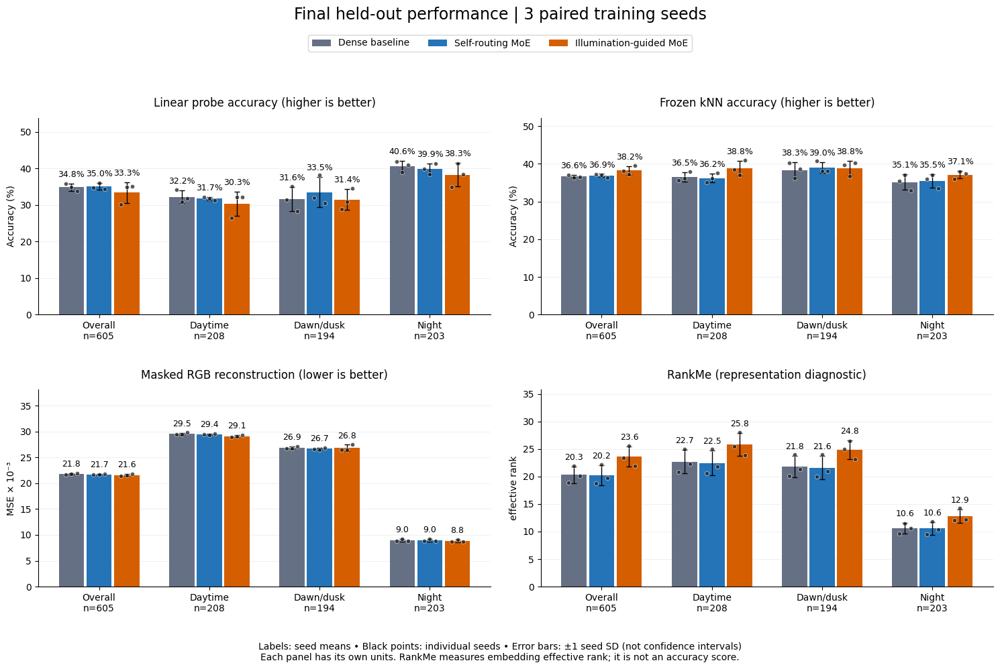

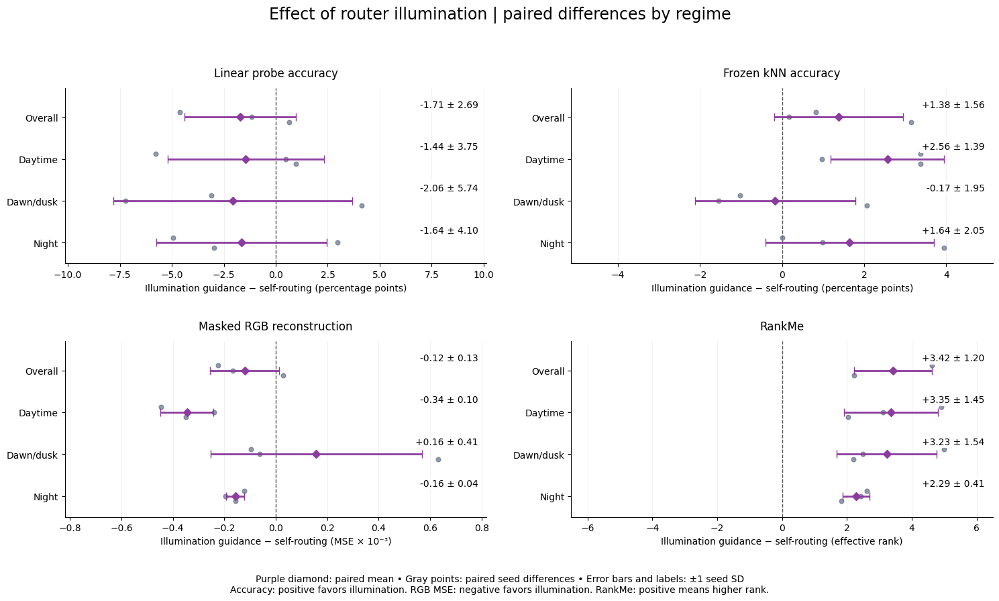

Rendered saved metrics from run: 20261029T095722425903Z
C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-illumination-comparison\20261029T095722425903Z\external_performance_by_regime.png
C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-illumination-comparison\20261029T095722425903Z\external_illumination_vs_self.png


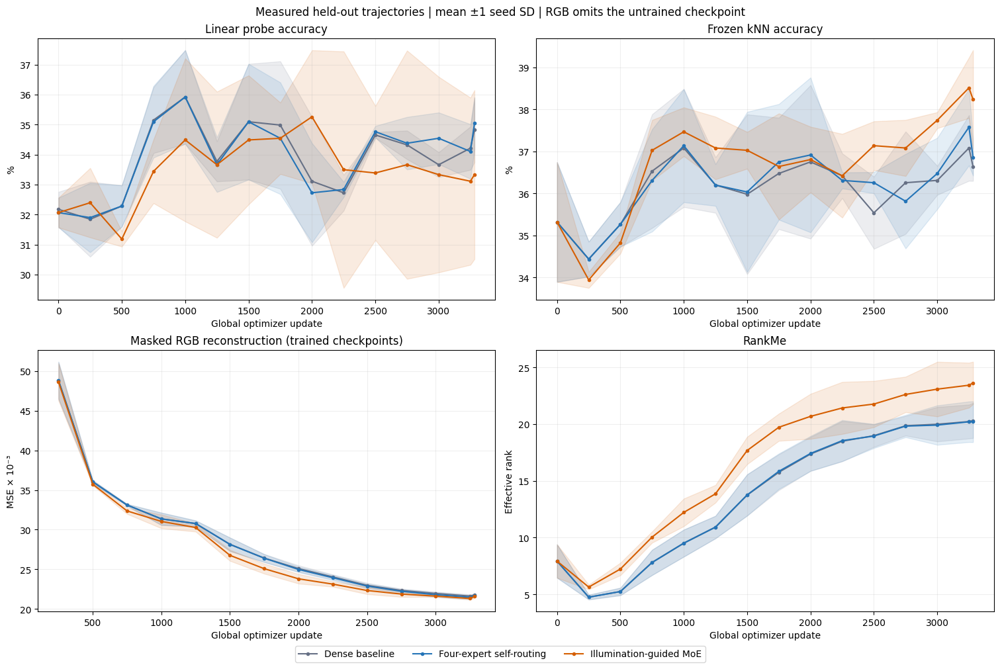

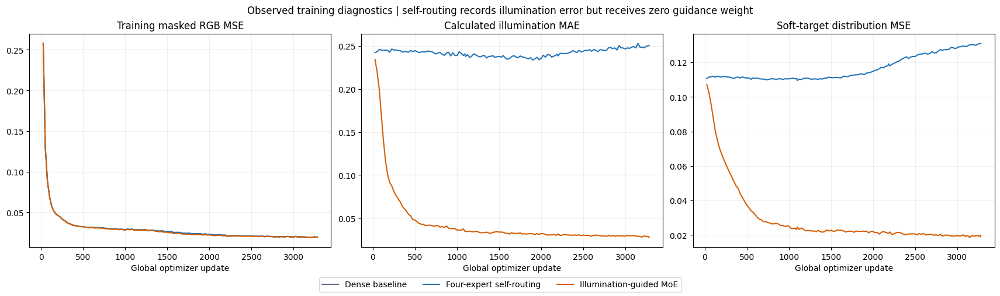

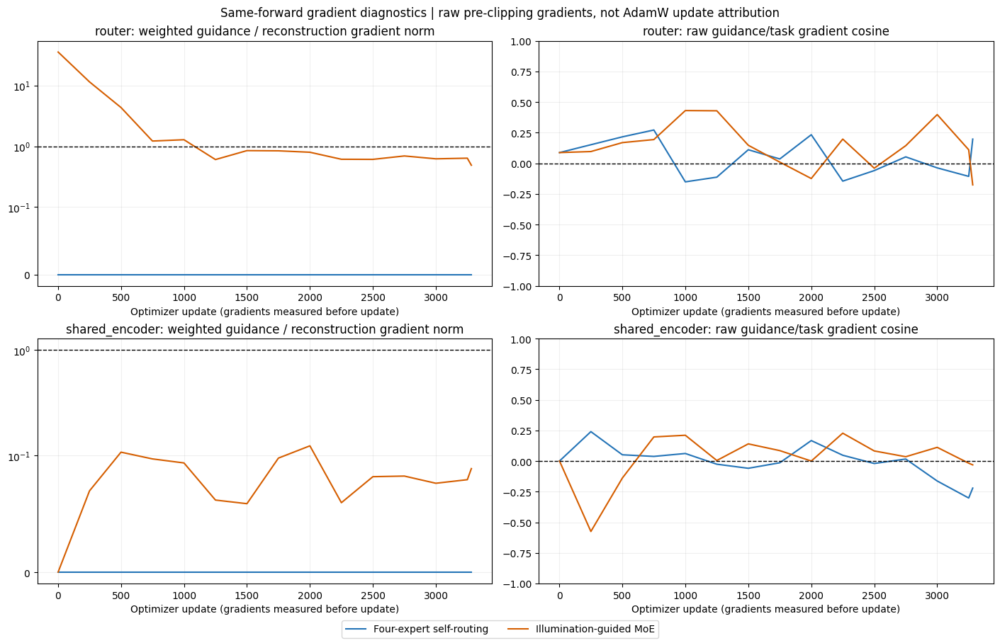

,regime,arm,baseline,metric,seeds,mean_delta,seed_sd,ci95_low,ci95_high
4,all,illum_moe,self_moe,knn_accuracy,3,1.377410,1.562253,-2.503441,5.258262
5,all,illum_moe,self_moe,linear_accuracy,3,-1.707989,2.687327,-8.383680,4.967703
6,all,illum_moe,self_moe,masked_rgb_mse,3,-0.000121,0.000134,-0.000453,0.000211
7,all,illum_moe,self_moe,rankme,3,3.420436,1.203194,0.431537,6.409335


In [12]:
from pathlib import Path

import matplotlib.pyplot as performance_plt
import numpy as np
import pandas as pd
from IPython.display import display as show

# Set a saved run folder here to redraw these figures without training.
performance_run_dir = None
if performance_run_dir is None:
    if "run_dir" in globals():
        performance_run_dir = Path(run_dir)
    else:
        performance_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir())
        performance_files = sorted(
            (performance_root / "outputs/moe-router-illumination-comparison").glob("*/external_metrics_by_step.csv")
        )
        if not performance_files:
            raise FileNotFoundError("No saved external metrics. Run evaluation or set performance_run_dir.")
        performance_run_dir = performance_files[-1].parent
performance_run_dir = Path(performance_run_dir)
performance_data = pd.read_csv(performance_run_dir / "external_metrics_by_step.csv")
performance_regimes = ["all", "daytime", "dawn/dusk", "night"]
performance_regime_labels = ["Overall", "Daytime", "Dawn/dusk", "Night"]
performance_arms = ["dense", "self_moe", "illum_moe"]
performance_arm_labels = ["Dense baseline", "Self-routing MoE", "Illumination-guided MoE"]
performance_colors = ["#667085", "#2474b7", "#d55e00"]
performance_specs = [
    ("linear_accuracy", "Linear probe accuracy", 100.0, "%", "higher is better"),
    ("knn_accuracy", "Frozen kNN accuracy", 100.0, "%", "higher is better"),
    ("masked_rgb_mse", "Masked RGB reconstruction", 1000.0, "MSE × 10⁻³", "lower is better"),
    ("rankme", "RankMe", 1.0, "effective rank", "representation diagnostic"),
]
performance_final = performance_data.loc[
    performance_data["stage"].eq("final")
    & performance_data["arm"].isin(performance_arms)
    & performance_data["regime"].isin(performance_regimes)
].copy()
performance_seeds = sorted(performance_final["seed"].unique())
performance_index = pd.MultiIndex.from_product(
    [performance_seeds, performance_arms, performance_regimes], names=["seed", "arm", "regime"]
)
performance_panel = performance_final.set_index(["seed", "arm", "regime"])
if not performance_seeds or not performance_panel.index.is_unique:
    raise ValueError("Expected unique final seed/arm/regime results.")
if not performance_index.isin(performance_panel.index).all():
    raise ValueError("Each arm needs the same seeds and regimes for a paired comparison.")
performance_panel = performance_panel.reindex(performance_index)
performance_columns = [spec[0] for spec in performance_specs]
if not np.isfinite(performance_panel[performance_columns].to_numpy()).all():
    raise ValueError("Missing or nonfinite performance values.")
if (performance_final.groupby("regime")["images"].nunique() != 1).any():
    raise ValueError("Compared arms must use equal held-out sample counts within each regime.")
performance_counts = performance_final.groupby("regime")["images"].first().reindex(performance_regimes)
performance_fig, performance_axes = performance_plt.subplots(2, 2, figsize=(15, 10))
performance_summary_rows = []
for performance_ax, (
    performance_metric,
    performance_title,
    performance_scale,
    performance_unit,
    performance_direction,
) in zip(performance_axes.flat, performance_specs, strict=True):
    performance_max = 0.0
    for arm_index, (performance_arm, performance_label, performance_color) in enumerate(
        zip(performance_arms, performance_arm_labels, performance_colors, strict=True)
    ):
        performance_values = (
            performance_panel.xs(performance_arm, level="arm")[performance_metric]
            .unstack("regime")
            .reindex(index=performance_seeds, columns=performance_regimes)
            .to_numpy()
            * performance_scale
        )
        performance_means = performance_values.mean(axis=0)
        performance_sd = (
            performance_values.std(axis=0, ddof=1) if len(performance_seeds) > 1 else np.zeros(len(performance_regimes))
        )
        performance_x = np.arange(len(performance_regimes)) + (arm_index - 1) * 0.25
        performance_bars = performance_ax.bar(
            performance_x,
            performance_means,
            width=0.23,
            yerr=performance_sd if len(performance_seeds) > 1 else None,
            capsize=3,
            color=performance_color,
            label=performance_label,
            error_kw={"elinewidth": 1, "capthick": 1},
            zorder=2,
        )
        performance_ax.bar_label(
            performance_bars,
            labels=[f"{v:.1f}{'%' if performance_unit == '%' else ''}" for v in performance_means],
            padding=5,
            fontsize=9,
        )
        for seed_index, _performance_seed in enumerate(performance_seeds):
            performance_jitter = 0.10 * (seed_index / max(1, len(performance_seeds) - 1) - 0.5)
            performance_ax.scatter(
                performance_x + performance_jitter,
                performance_values[seed_index],
                color="#202020",
                edgecolors="white",
                linewidths=0.5,
                alpha=0.75,
                s=20,
                zorder=4,
            )
        performance_max = max(performance_max, float((performance_means + performance_sd).max()))
        for regime_index, performance_regime in enumerate(performance_regimes):
            performance_summary_rows.append(
                {
                    "arm": performance_arm,
                    "regime": performance_regime,
                    "metric": performance_metric,
                    "seeds": len(performance_seeds),
                    "query_images": int(performance_counts.iloc[regime_index]),
                    "mean": performance_means[regime_index] / performance_scale,
                    "seed_sd": performance_sd[regime_index] / performance_scale
                    if len(performance_seeds) > 1
                    else np.nan,
                }
            )
    performance_ax.set_title(f"{performance_title} ({performance_direction})", fontsize=12, pad=12)
    performance_ax.set_ylabel("Accuracy (%)" if performance_unit == "%" else performance_unit)
    performance_ax.set_xticks(
        range(len(performance_regimes)),
        [f"{name}\nn={int(count)}" for name, count in zip(performance_regime_labels, performance_counts, strict=True)],
    )
    performance_ax.set_ylim(0, min(100, performance_max * 1.28) if performance_unit == "%" else performance_max * 1.28)
    performance_ax.yaxis.grid(True, alpha=0.18, zorder=0)
    performance_ax.spines[["top", "right"]].set_visible(False)
performance_fig.suptitle(
    f"Final held-out performance | {len(performance_seeds)} paired training seeds", fontsize=17, y=0.99
)
performance_handles, performance_labels = performance_axes[0, 0].get_legend_handles_labels()
performance_fig.legend(performance_handles, performance_labels, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=3)
performance_fig.text(
    0.5,
    0.015,
    "Labels: seed means • Black points: individual seeds • Error bars: ±1 seed SD (not confidence intervals)\n"
    "Each panel has its own units. RankMe measures embedding effective rank; it is not an accuracy score.",
    ha="center",
    fontsize=10,
)
performance_fig.tight_layout(rect=(0, 0.07, 1, 0.91), h_pad=3, w_pad=2)
for performance_suffix in ["png", "pdf"]:
    performance_fig.savefig(performance_run_dir / f"external_performance_by_regime.{performance_suffix}", dpi=180)
pd.DataFrame(performance_summary_rows).to_csv(performance_run_dir / "external_performance_summary.csv", index=False)
show(performance_fig)
performance_plt.close(performance_fig)

# Pair each illumination result with the same self-routing training seed.
performance_delta_fig, performance_delta_axes = performance_plt.subplots(2, 2, figsize=(15, 9))
performance_delta_rows = []
for performance_ax, (
    performance_metric,
    performance_title,
    performance_scale,
    performance_unit,
    _performance_direction,
) in zip(performance_delta_axes.flat, performance_specs, strict=True):
    performance_self = performance_panel.xs("self_moe", level="arm")[performance_metric].unstack("regime")
    performance_class = performance_panel.xs("illum_moe", level="arm")[performance_metric].unstack("regime")
    performance_deltas = (performance_class - performance_self).reindex(
        index=performance_seeds, columns=performance_regimes
    ) * performance_scale
    performance_delta_mean = performance_deltas.mean(axis=0).to_numpy()
    performance_delta_sd = (
        performance_deltas.std(axis=0, ddof=1).to_numpy()
        if len(performance_seeds) > 1
        else np.zeros(len(performance_regimes))
    )
    performance_y = np.arange(len(performance_regimes))
    performance_ax.axvline(0, color="#555555", linestyle="--", linewidth=1)
    for seed_index, performance_seed in enumerate(performance_seeds):
        performance_jitter = 0.24 * (seed_index / max(1, len(performance_seeds) - 1) - 0.5)
        performance_ax.scatter(
            performance_deltas.loc[performance_seed],
            performance_y + performance_jitter,
            color="#667085",
            alpha=0.7,
            s=23,
            zorder=3,
        )
        for performance_regime in performance_regimes:
            performance_delta_rows.append(
                {
                    "seed": performance_seed,
                    "regime": performance_regime,
                    "metric": performance_metric,
                    "illumination_minus_self": performance_deltas.loc[performance_seed, performance_regime]
                    / performance_scale,
                }
            )
    performance_ax.errorbar(
        performance_delta_mean,
        performance_y,
        xerr=performance_delta_sd if len(performance_seeds) > 1 else None,
        fmt="D",
        color="#8b3c9e",
        markersize=6,
        capsize=4,
        linewidth=2,
        zorder=4,
    )
    performance_limit = (
        max(
            float(np.abs(performance_deltas.to_numpy()).max()),
            float((np.abs(performance_delta_mean) + performance_delta_sd).max()),
            0.01,
        )
        * 1.3
    )
    performance_ax.set_xlim(-performance_limit, performance_limit)
    performance_ax.set_ylim(3.5, -0.7)
    performance_ax.set_yticks(performance_y, performance_regime_labels)
    performance_delta_unit = "percentage points" if performance_unit == "%" else performance_unit
    performance_ax.set_xlabel(f"Illumination guidance − self-routing ({performance_delta_unit})")
    performance_ax.set_title(performance_title, fontsize=12, pad=12)
    performance_ax.spines[["top", "right"]].set_visible(False)
    performance_ax.xaxis.grid(True, alpha=0.18)
    for regime_index, performance_value in enumerate(performance_delta_mean):
        performance_sd_text = f" ± {performance_delta_sd[regime_index]:.2f}" if len(performance_seeds) > 1 else ""
        performance_ax.text(
            0.98,
            regime_index - 0.30,
            f"{performance_value:+.2f}{performance_sd_text}",
            transform=performance_ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 2},
        )
performance_delta_fig.suptitle("Effect of router illumination | paired differences by regime", fontsize=17, y=0.99)
performance_delta_fig.text(
    0.5,
    0.02,
    "Purple diamond: paired mean • Gray points: paired seed differences • Error bars and labels: ±1 seed SD\n"
    "Accuracy: positive favors illumination. RGB MSE: negative favors illumination. "
    "RankMe: positive means higher rank.",
    ha="center",
    fontsize=10,
)
performance_delta_fig.tight_layout(rect=(0, 0.08, 1, 0.95), h_pad=3, w_pad=2)
for performance_suffix in ["png", "pdf"]:
    performance_delta_fig.savefig(performance_run_dir / f"external_illumination_vs_self.{performance_suffix}", dpi=180)
pd.DataFrame(performance_delta_rows).to_csv(performance_run_dir / "external_illumination_vs_self.csv", index=False)
show(performance_delta_fig)
performance_plt.close(performance_delta_fig)
print(f"Rendered saved metrics from run: {performance_run_dir.name}")
print(performance_run_dir / "external_performance_by_regime.png")
print(performance_run_dir / "external_illumination_vs_self.png")
metric_specs = [
    ("linear_accuracy", "Linear probe accuracy", 100, "%"),
    ("knn_accuracy", "Frozen kNN accuracy", 100, "%"),
    ("masked_rgb_mse", "Masked RGB reconstruction", 1000, "MSE × 10⁻³"),
    ("rankme", "RankMe", 1, "Effective rank"),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for ax, (metric, title, scale, unit) in zip(axes.flat, metric_specs, strict=True):
    for arm in arm_names:
        part = metrics.loc[metrics["arm"].eq(arm) & metrics["regime"].eq("all")]
        if metric == "masked_rgb_mse":
            part = part.loc[part["global_step"].gt(0)]
        stats = part.groupby("global_step")[metric].agg(["mean", "std"])
        x, mean = stats.index.to_numpy(), stats["mean"].to_numpy() * scale
        spread = stats["std"].fillna(0).to_numpy() * scale
        ax.plot(x, mean, "o-", color=arm_colors[arm], label=arm_labels[arm], markersize=3)
        ax.fill_between(x, mean - spread, mean + spread, color=arm_colors[arm], alpha=0.12)
    ax.set(
        title=title + (" (trained checkpoints)" if metric == "masked_rgb_mse" else ""),
        xlabel="Global optimizer update",
        ylabel=unit,
    )
    ax.grid(alpha=0.2)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Measured held-out trajectories | mean ±1 seed SD | RGB omits the untrained checkpoint")
fig.savefig(run_dir / "heldout_step_curves.png", dpi=150)
show(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, metric, title in zip(
    axes,
    ["reconstruction", "illumination_level_mae", "distribution_mse"],
    ["Training masked RGB MSE", "Calculated illumination MAE", "Soft-target distribution MSE"],
    strict=True,
):
    for arm in arm_names:
        if arm == "dense" and metric != "reconstruction":
            continue
        part = training.loc[training["arm"].eq(arm)]
        values = part.groupby("global_step")[metric].mean()
        ax.plot(values.index, values, color=arm_colors[arm], label=arm_labels[arm])
    ax.set(title=title, xlabel="Global optimizer update")
    ax.grid(alpha=0.2)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    "Observed training diagnostics | self-routing records illumination error but receives zero guidance weight"
)
fig.savefig(run_dir / "training_diagnostics.png", dpi=150)
show(fig)
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for row, group in enumerate(["router", "shared_encoder"]):
    for arm in ["self_moe", "illum_moe"]:
        part = gradients.loc[gradients["arm"].eq(arm) & gradients["group"].eq(group)]
        for ax, metric in zip(
            axes[row], ["weighted_guidance_to_reconstruction", "guidance_vs_reconstruction_cosine"], strict=True
        ):
            values = part.groupby("global_step")[metric].mean()
            ax.plot(values.index, values, color=arm_colors[arm], label=arm_labels[arm])
    axes[row, 0].set_yscale("symlog", linthresh=0.1)
    axes[row, 0].axhline(1, color="black", linestyle="--", linewidth=1)
    axes[row, 0].set_title(f"{group}: weighted guidance / reconstruction gradient norm")
    axes[row, 1].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[row, 1].set(title=f"{group}: raw guidance/task gradient cosine", ylim=(-1, 1))
    for ax in axes[row]:
        ax.set_xlabel("Optimizer update (gradients measured before update)")
        ax.grid(alpha=0.2)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Same-forward gradient diagnostics | raw pre-clipping gradients, not AdamW update attribution")
fig.savefig(run_dir / "guidance_gradient_diagnostics.png", dpi=150)
show(fig)
plt.close(fig)

final_metrics = metrics.loc[metrics["global_step"].eq(total_updates)]
paired_rows = []
for (seed, regime), part in final_metrics.groupby(["seed", "regime"]):
    indexed = part.set_index("arm")
    for metric, _title, _scale, _unit in metric_specs:
        delta_scale = 100 if metric.endswith("accuracy") else 1
        for arm, baseline in [("self_moe", "dense"), ("illum_moe", "dense"), ("illum_moe", "self_moe")]:
            paired_rows.append(
                {
                    "seed": seed,
                    "regime": regime,
                    "arm": arm,
                    "baseline": baseline,
                    "metric": metric,
                    "delta": delta_scale * (indexed.loc[arm, metric] - indexed.loc[baseline, metric]),
                }
            )
paired = pd.DataFrame(paired_rows)
paired.to_csv(run_dir / "paired_deltas.csv", index=False)
paired_summary_rows = []
for keys, part in paired.groupby(["regime", "arm", "baseline", "metric"]):
    values = part["delta"].to_numpy()
    spread = values.std(ddof=1) if len(values) > 1 else float("nan")
    half = student_t.ppf(0.975, len(values) - 1) * spread / np.sqrt(len(values)) if len(values) > 1 else float("nan")
    paired_summary_rows.append(
        {
            **dict(zip(["regime", "arm", "baseline", "metric"], keys, strict=True)),
            "seeds": len(values),
            "mean_delta": values.mean(),
            "seed_sd": spread,
            "ci95_low": values.mean() - half,
            "ci95_high": values.mean() + half,
        }
    )
paired_summary = pd.DataFrame(paired_summary_rows)
paired_summary.to_csv(run_dir / "paired_summary.csv", index=False)
show(paired_summary.loc[paired_summary["regime"].eq("all") & paired_summary["baseline"].eq("self_moe")])
final_metrics.groupby(["arm", "regime"])[[s[0] for s in metric_specs]].agg(["mean", "std"]).to_csv(
    run_dir / "endpoint_summary.csv"
)

## Expert CKA, weighted utilization, activation and routing calibration

Read actual saved measurements. Means and error bars describe training-seed variability.

In [ ]:
def load_trained_models(seed: int) -> dict[str, torch.nn.Module]:
    """Strictly load this notebook's completed checkpoints without resetting trained weights."""
    with torch.random.fork_rng(devices=[]):
        models = initialize_arms(seed)
    for spec in arms:
        arm = spec["name"]
        checkpoint = torch.load(
            run_dir / f"seed_{seed}/{arm}/checkpoint_last.pt", map_location="cpu", weights_only=True
        )
        if (checkpoint["arm"], checkpoint["seed"], checkpoint["protocol_hash"], checkpoint["global_step"]) != (
            spec,
            seed,
            protocol_hash,
            total_updates,
        ):
            raise ValueError("Expected completed checkpoints from this exact illumination protocol.")
        models[arm].load_state_dict(checkpoint["method"], strict=True)
        models[arm].eval()
    return models


cka_metrics = pd.read_csv(run_dir / "expert_cka.csv")
activation_metrics = pd.read_csv(run_dir / "expert_activation_frequency.csv")
entropy_metrics = pd.read_csv(run_dir / "expert_utilization_entropy.csv")
fig, axes = plt.subplots(len(seeds), 2, figsize=(12, 3.8 * len(seeds)), squeeze=False, constrained_layout=True)
for row, seed in enumerate(seeds):
    for col, arm in enumerate(["self_moe", "illum_moe"]):
        part = cka_metrics.loc[
            cka_metrics["seed"].eq(seed) & cka_metrics["arm"].eq(arm) & cka_metrics["kind"].eq("within_arm")
        ]
        matrix = (
            part.pivot(index="expert_i", columns="expert_j", values="cka")
            .reindex(index=range(num_experts), columns=range(num_experts))
            .to_numpy()
        )
        image = axes[row, col].imshow(matrix, vmin=0, vmax=1, cmap="viridis")
        axes[row, col].set(title=f"{arm_labels[arm]} | seed {seed}", xlabel="Expert", ylabel="Expert")
        axes[row, col].set_xticks(range(num_experts))
        axes[row, col].set_yticks(range(num_experts))
        for i, j in np.ndindex(matrix.shape):
            axes[row, col].text(
                j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", color="black" if matrix[i, j] > 0.65 else "white"
            )
fig.colorbar(image, ax=axes.ravel().tolist(), label="Common-input linear CKA")
fig.suptitle(f"Expert representations at final MoE block {analysis_block} | lower CKA alone is not better performance")
fig.savefig(run_dir / "expert_cka.png", dpi=150)
show(fig)
plt.close(fig)
show(
    activation_metrics[["arm", "seed", "regime", "expert", "token_activation_frequency", "image_activation_frequency"]]
)
show(
    Markdown(
        "**All four experts execute for every patch. Actual token/image activation frequency is 100%.** "
        "The heatmaps show mixture contribution and dominant-weight frequency. Argmax is only a diagnostic."
    )
)

for metric, title in [
    ("mean_probability", "Actual mean mixture contribution"),
    ("dominant_frequency", "Fraction of patches where expert has the largest weight (diagnostic)"),
]:
    fig, axes = plt.subplots(len(seeds), 2, figsize=(12, 3.5 * len(seeds)), squeeze=False, constrained_layout=True)
    for row, seed in enumerate(seeds):
        for col, arm in enumerate(["self_moe", "illum_moe"]):
            part = activation_metrics.loc[activation_metrics["seed"].eq(seed) & activation_metrics["arm"].eq(arm)]
            matrix = (
                part.pivot(index="regime", columns="expert", values=metric)
                .reindex(index=regime_names, columns=range(num_experts))
                .to_numpy()
            )
            image = axes[row, col].imshow(np.ma.masked_invalid(matrix), vmin=0, vmax=1, cmap="Blues", aspect="auto")
            axes[row, col].set(title=f"{arm_labels[arm]} | seed {seed}", xlabel="Expert")
            axes[row, col].set_xticks(range(num_experts), [f"E{i}" for i in range(num_experts)])
            axes[row, col].set_yticks(range(3), regime_names)
            for i, j in np.ndindex(matrix.shape):
                axes[row, col].text(
                    j,
                    i,
                    f"{matrix[i, j]:.1%}" if np.isfinite(matrix[i, j]) else "n/a",
                    ha="center",
                    va="center",
                    color="white" if matrix[i, j] > 0.55 else "black",
                )
    fig.colorbar(image, ax=axes.ravel().tolist(), format="{x:.0%}", label=title)
    fig.suptitle(title + " | same fixed scale for both MoEs and all seeds")
    fig.savefig(run_dir / f"expert_{metric}_by_regime.png", dpi=150)
    show(fig)
    plt.close(fig)

fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True, constrained_layout=True)
for ax, regime in zip(axes, ["all", *regime_names], strict=True):
    for i, arm in enumerate(["self_moe", "illum_moe"]):
        values = entropy_metrics.loc[
            entropy_metrics["arm"].eq(arm) & entropy_metrics["regime"].eq(regime), "entropy_normalized"
        ].to_numpy()
        if len(values):
            ax.errorbar(
                values.mean(),
                i,
                xerr=values.std(ddof=1) if len(values) > 1 else None,
                fmt="o",
                color=arm_colors[arm],
                capsize=3,
            )
            ax.scatter(values, i + np.linspace(-0.08, 0.08, len(values)), color="black", s=13)
            ax.text(1.01, i, f"{values.mean():.3f}", va="center")
    ax.set(title=regime, xlabel="Normalized mixture-mass entropy", xlim=(0, 1.15))
    ax.set_yticks([0, 1], [arm_labels["self_moe"], arm_labels["illum_moe"]])
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle(
    "Weighted utilization entropy | 1 means equal average mixture weights, not distinct expert representations"
)
fig.savefig(run_dir / "expert_utilization_entropy.png", dpi=150)
show(fig)
plt.close(fig)

# Cache full-query unmasked routing for illumination and condition analyses, independently of the 512-image CKA cap.
analysis_dir = run_dir / "illumination_condition_analysis"
analysis_dir.mkdir(exist_ok=True)
query_frame = frames["query"].copy()
attributes = {
    **read_bdd_attributes(dataset_root, "train"),
    **read_bdd_attributes(dataset_root, "val"),
}
query_frame["weather"] = [attributes[r.clip_id].get("weather", "(missing)") for r in query_frame.itertuples()]
for row in query_frame.itertuples():
    if (attributes[row.clip_id]["timeofday"], attributes[row.clip_id]["scene"]) != (row.regime, row.scene):
        raise ValueError("Post-hoc attributes disagree with the saved query panel.")
analysis_contract = {
    "version": 1,
    "protocol_hash": protocol_hash,
    "labels_sha256": hashlib.sha256(json.dumps(attributes, sort_keys=True).encode()).hexdigest(),
    "checkpoints": {
        f"{seed}/{arm}": hashlib.sha256((run_dir / f"seed_{seed}/{arm}/checkpoint_last.pt").read_bytes()).hexdigest()
        for seed in seeds
        for arm in ["self_moe", "illum_moe"]
    },
}
cache_manifest = analysis_dir / "manifest.json"
per_image_path = analysis_dir / "per_image_routing.csv"
if cache_manifest.exists():
    manifest = json.loads(cache_manifest.read_text())
    if (
        manifest["contract"] != analysis_contract
        or hashlib.sha256(per_image_path.read_bytes()).hexdigest() != manifest["per_image_sha256"]
    ):
        raise ValueError("Frozen analysis cache/provenance mismatch.")
    per_image = pd.read_csv(per_image_path)
else:
    analysis_rows = []
    for seed in seeds:
        models = load_trained_models(seed)
        for arm in ["self_moe", "illum_moe"]:
            model = models[arm].to(device).eval()
            probabilities, levels = [], []
            with torch.no_grad():
                for cpu_images, _unused_scenes, _unused_regimes in loader(records["query"], seed):
                    images = cpu_images.to(device)
                    probabilities.append(model.encoder.routing(images)[analysis_block][:, 1:, :].cpu().numpy())
                    levels.append(patch_illumination(images).cpu().numpy())
            probabilities, levels = np.concatenate(probabilities), np.concatenate(levels)
            np.savez_compressed(
                analysis_dir / f"seed_{seed}_{arm}_patches.npz", probabilities=probabilities, levels=levels
            )
            for i, row in enumerate(query_frame.to_dict("records")):
                dominant = np.eye(num_experts)[probabilities[i].argmax(-1)].mean(0)
                for expert in range(num_experts):
                    analysis_rows.append(
                        {
                            **{k: row[k] for k in ["clip_id", "regime", "weather", "scene"]},
                            "arm": arm,
                            "seed": seed,
                            "expert": expert,
                            "mean_probability": probabilities[i, :, expert].mean(),
                            "dominant_frequency": dominant[expert],
                            "mean_observed_illumination": levels[i].mean(),
                        }
                    )
            model.cpu()
        del models
    per_image = pd.DataFrame(analysis_rows)
    per_image.to_csv(per_image_path, index=False)
    cache_manifest.write_text(
        dumps_valid(
            {"contract": analysis_contract, "per_image_sha256": hashlib.sha256(per_image_path.read_bytes()).hexdigest()}
        ),
        encoding="utf-8",
    )

fig, axes = plt.subplots(len(seeds), 2, figsize=(13, 3.6 * len(seeds)), squeeze=False, constrained_layout=True)
illumination_summary = []
for row, seed in enumerate(seeds):
    for col, arm in enumerate(["self_moe", "illum_moe"]):
        with np.load(analysis_dir / f"seed_{seed}_{arm}_patches.npz") as cache:
            probability, level = cache["probabilities"], cache["levels"]
        expected = (probability * np.linspace(0, 1, num_experts)).sum(-1)
        illumination_summary.append(
            {
                "arm": arm,
                "seed": seed,
                "images": len(level),
                "patches": level.size,
                "illumination_mae": np.abs(expected - level).mean(),
                "illumination_rmse": np.sqrt(np.square(expected - level).mean()),
            }
        )
        bins = np.minimum((level * 20).astype(int), 19)
        for expert in range(num_experts):
            means = [probability[..., expert][bins == b].mean() if (bins == b).any() else np.nan for b in range(20)]
            axes[row, col].plot(
                (np.arange(20) + 0.5) / 20, means, "o-", color=expert_colors[expert], label=f"E{expert}", markersize=3
            )
        axes[row, col].set(
            title=f"{arm_labels[arm]} | seed {seed}",
            xlabel="Calculated patch illumination",
            ylabel="Mean mixture weight",
            ylim=(0, 1),
        )
        axes[row, col].grid(alpha=0.2)
        axes[row, col].legend(ncol=4)
fig.suptitle("Do the four experts learn the intended illumination ordering? | full held-out query panel")
fig.savefig(analysis_dir / "expert_weight_vs_illumination.png", dpi=150)
show(fig)
plt.close(fig)
illumination_summary = pd.DataFrame(illumination_summary)
illumination_summary.to_csv(analysis_dir / "illumination_regression_metrics.csv", index=False)
show(illumination_summary)

condition_plot_seeds = [seeds[0]]
condition_min_images = 5


def plot_condition_mixtures(dimensions: list[str], seed: int, subset_regime: str | None = None) -> None:
    """Compare actual mean mixture contributions within BDD conditions, masking sparse observations."""
    selected = per_image.loc[per_image["seed"].eq(seed)]
    if subset_regime is not None:
        selected = selected.loc[selected["regime"].eq(subset_regime)]
    grouped = (
        selected.groupby(["arm", *dimensions, "expert"])
        .agg(images=("clip_id", "nunique"), weight=("mean_probability", "mean"))
        .reset_index()
    )
    condition_name = (subset_regime or "all").replace("/", "-")
    grouped.to_csv(analysis_dir / ("_".join(dimensions) + f"_{condition_name}_seed_{seed}.csv"), index=False)
    keys = sorted(set(grouped[dimensions].itertuples(index=False, name=None)))
    if not keys:
        print(f"No observed conditions for {subset_regime} in this capped evaluation panel.")
        return
    index = pd.MultiIndex.from_tuples(keys, names=dimensions)
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(keys) * 0.35 + 2.5)), constrained_layout=True)
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#e6e8eb")
    for ax, arm in zip(axes, ["self_moe", "illum_moe"], strict=True):
        part = grouped.loc[grouped["arm"].eq(arm)]
        counts = part.groupby(dimensions)["images"].first().reindex(index)
        matrix = (
            part.pivot(index=dimensions, columns="expert", values="weight")
            .reindex(index=index, columns=range(num_experts))
            .to_numpy(copy=True)
        )
        matrix[counts.to_numpy() < condition_min_images] = np.nan
        image = ax.imshow(np.ma.masked_invalid(matrix), vmin=0, vmax=1, cmap=cmap, aspect="auto")
        ax.set_xticks(range(num_experts), [f"E{i}" for i in range(num_experts)])
        ax.set_yticks(
            range(len(keys)), [" | ".join(k) + f" (n={int(n)})" for k, n in zip(keys, counts, strict=True)], fontsize=9
        )
        ax.set_title(arm_labels[arm])
        for i, j in np.ndindex(matrix.shape):
            ax.text(
                j,
                i,
                f"{matrix[i, j]:.1%}" if np.isfinite(matrix[i, j]) else "—",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if matrix[i, j] > 0.55 else "black",
            )
    fig.colorbar(
        image, ax=axes.tolist(), format="{x:.0%}", label="Mean mixture coefficient (actual contribution weight)"
    )
    fig.suptitle(
        f"Expert contribution by {' × '.join(dimensions)} | {subset_regime or 'all regimes'} | seed {seed}\n"
        f"Gray: fewer than {condition_min_images} images; labels are evaluation attributes only"
    )
    fig.savefig(analysis_dir / ("_".join(dimensions) + f"_{condition_name}_seed_{seed}.png"), dpi=150)
    show(fig)
    plt.close(fig)


for seed in condition_plot_seeds:
    plot_condition_mixtures(["regime", "weather"], seed)
    plot_condition_mixtures(["regime", "scene"], seed)
    for regime in regime_names:
        plot_condition_mixtures(["regime", "weather", "scene"], seed, regime)

# Pixel reconstruction preview: same real query image and mask in every arm; clipping is display-only.
preview_models = load_trained_models(video_seed)
preview_records = [
    next(r for r in records["query"] if r["regime"] == regime)
    for regime in regime_names
    if any(r["regime"] == regime for r in records["query"])
]
fig, axes = plt.subplots(
    len(preview_records), 5, figsize=(15, 3.4 * len(preview_records)), squeeze=False, constrained_layout=True
)
with torch.no_grad():
    for row_index, record in enumerate(preview_records):
        image = next(iter(loader([record], video_seed)))[0].to(device)
        patches = patchify(image, patch_size)
        mask_noise = fixed_masks[0:1].to(device)
        axes[row_index, 0].imshow(image[0].clamp(0, 1).cpu().permute(1, 2, 0))
        axes[row_index, 0].set_title(record["regime"] + " | input")
        for col, arm in enumerate(arm_names, 2):
            model = preview_models[arm].to(device).eval()
            result = model.encoder.forward_with_aux(image, mask_ratio=mask_ratio, mask_noise=mask_noise)
            prediction = model.decoder(result.tokens, result.ids_restore)
            mask = result.mask[..., None]
            composite = patches * (1 - mask) + prediction * mask
            error = ((prediction - patches).square().mean(-1) * result.mask).sum() / result.mask.sum()
            axes[row_index, col].imshow(unpatchify(composite, patch_size, 3)[0].clamp(0, 1).cpu().permute(1, 2, 0))
            axes[row_index, col].set_title(f"{arm_labels[arm]}\nmasked MSE {float(error):.4f}")
            if col == 2:
                axes[row_index, 1].imshow(
                    unpatchify(patches * (1 - mask), patch_size, 3)[0].clamp(0, 1).cpu().permute(1, 2, 0)
                )
                axes[row_index, 1].set_title("Visible patches")
            model.cpu()
        for ax in axes[row_index]:
            ax.axis("off")
fig.suptitle(
    "Paired RGB reconstruction | visible pixels retained; predictions fill masked patches | display clipped only"
)
fig.savefig(run_dir / "paired_rgb_reconstructions.png", dpi=150)
show(fig)
plt.close(fig)
del preview_models

## Frozen same-video comparisons

Both MoEs process the same original frames, with continuous probability maps from the final MoE
block. These are router-weight maps, not gradient-attribution maps. The overall map identifies
the largest weight per patch; it does not mean only one expert executes. Stacked areas show actual
mean mixture coefficients and total 100% per frame. Video predictions have no framewise scene ground
truth, so scene readouts are predictions rather than reported accuracy. Tunnel phase descriptions
are editorial observations; matched highway/weather/time labels describe source clips only.

In [14]:
video_models, video_readouts = {}, {}


def prepare_video_models() -> None:
    """Load final checkpoints and fit only frozen scene readouts on the fixed support stills."""
    if video_models:
        return
    video_models.update(load_trained_models(video_seed))
    for arm, model in video_models.items():
        model.to(device).eval()
        _rows, readout = external_evaluation(model, arm, video_seed, "video_readout")
        video_readouts[arm] = {name: readout[name] for name in ["linear", "knn"]}
        model.cpu()


def sample_source_video(source: dict[str, Any], duration: float) -> Iterator[tuple[int, float, np.ndarray]]:
    """Read source frames in capture order, selecting the first frame at/after each requested output time."""
    path = Path(source["path"])
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise OSError(f"Cannot decode source video: {path}")
    source_fps = float(capture.get(cv2.CAP_PROP_FPS))
    if not math.isfinite(source_fps) or source_fps <= 0:
        capture.release()
        raise ValueError("Source video has no usable frame rate.")
    start = float(source.get("start_seconds", 0))
    required = int(round(duration * video_fps))
    frame_index, output_index = -1, 0
    try:
        while output_index < required:
            ok, bgr = capture.read()
            if not ok:
                raise ValueError(f"Source ended before the requested {duration}s segment: {path}")
            frame_index += 1
            source_seconds = frame_index / source_fps
            if source_seconds + 1e-9 < start + output_index / video_fps:
                continue
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            while output_index < required and source_seconds + 1e-9 >= start + output_index / video_fps:
                yield frame_index, source_seconds, rgb
                output_index += 1
    finally:
        capture.release()


def video_frame_stream(sources: list[dict[str, Any]]) -> Iterator[tuple[dict, int, float, float, np.ndarray]]:
    """Concatenate real, ordered source segments without synthesizing illumination or interpolated frames."""
    output_index = 0
    for source in sources:
        for frame_index, source_seconds, rgb in sample_source_video(source, source["segment_seconds"]):
            yield source, frame_index, source_seconds, output_index / video_fps, rgb
            output_index += 1


def routing_mosaic(rgb: np.ndarray, probabilities: np.ndarray, arm: str, seconds: float, clip_id: str) -> np.ndarray:
    """Show original, dominant-weight map and all four unthresholded probability maps on a shared scale."""
    width, height = 256, 144
    base = cv2.resize(rgb, (width, height), interpolation=cv2.INTER_AREA)
    grid = img_size // patch_size
    palette = np.array([[int(color[i : i + 2], 16) for i in [1, 3, 5]] for color in expert_colors], dtype=np.uint8)
    dominant = probabilities.argmax(-1).reshape(grid, grid)
    dominant_rgb = cv2.resize(palette[dominant], (width, height), interpolation=cv2.INTER_NEAREST)
    tiles = [base, cv2.addWeighted(base, 0.45, dominant_rgb, 0.55, 0)]
    titles = ["Original", "Largest weight (diagnostic)"]
    for expert in range(num_experts):
        weights = cv2.resize(
            probabilities[:, expert].reshape(grid, grid), (width, height), interpolation=cv2.INTER_LINEAR
        )
        heat = cv2.cvtColor(
            cv2.applyColorMap(np.rint(weights.clip(0, 1) * 255).astype(np.uint8), cv2.COLORMAP_TURBO), cv2.COLOR_BGR2RGB
        )
        tiles.append(cv2.addWeighted(base, 0.40, heat, 0.60, 0))
        titles.append(f"E{expert}: mean weight {probabilities[:, expert].mean():.1%}")
    labeled = []
    for tile, title in zip(tiles, titles, strict=True):
        panel = np.full((height + 26, width, 3), 245, dtype=np.uint8)
        panel[26:] = tile
        cv2.putText(panel, title, (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.43, (20, 20, 20), 1, cv2.LINE_AA)
        labeled.append(panel)
    row = np.hstack(labeled)
    header = np.full((30, row.shape[1], 3), 20, dtype=np.uint8)
    text = f"{arm_labels[arm]} | {seconds:.2f}s | {clip_id} | all 4 experts execute; heatmaps: 0 blue -> 1 red"
    cv2.putText(header, text, (8, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.49, (245, 245, 245), 1, cv2.LINE_AA)
    return np.vstack([header, row])


@torch.no_grad()
def export_routing_video(name: str, sources: list[dict[str, Any]]) -> dict[str, Any]:  # noqa: C901 - one synchronized decode/inference/encode lifecycle.
    """Stream three frozen models on identical frames; save H.264 and actual per-frame mixture/readout measurements."""
    prepare_video_models()
    executable = shutil.which("ffmpeg")
    if executable is None:
        raise FileNotFoundError("Install FFmpeg with libx264 before exporting videos.")
    source_ids = {s["clip_id"] for s in sources}
    if source_ids & {r["clip_id"] for split in records.values() for r in split}:
        raise ValueError("Video sources overlap training/support/query evaluation clips.")
    contract = {
        "version": 1,
        "protocol_hash": protocol_hash,
        "seed": video_seed,
        "fps": video_fps,
        "sources": [{**s, "sha256": hashlib.sha256(Path(s["path"]).read_bytes()).hexdigest()} for s in sources],
        "checkpoints": {
            arm: hashlib.sha256((run_dir / f"seed_{video_seed}/{arm}/checkpoint_last.pt").read_bytes()).hexdigest()
            for arm in arm_names
        },
    }
    key = hashlib.sha256(dumps_valid(contract).encode()).hexdigest()[:12]
    folder = run_dir / "videos" / f"{name}_{key}"
    folder.mkdir(parents=True, exist_ok=True)
    target, manifest_path = folder / "comparison.mp4", folder / "manifest.json"
    if manifest_path.exists():
        report = json.loads(manifest_path.read_text())
        if report["contract"] != contract or not target.exists() or not target.with_suffix(".csv").exists():
            raise ValueError("Saved video contract/files do not match the frozen models and sources.")
        return report
    partial = target.with_name("comparison.partial.mp4")
    process, rows, count = None, [], 0
    stream = video_frame_stream(sources)
    for model in video_models.values():
        model.to(device).eval()
    try:
        with target.with_suffix(".ffmpeg.log").open("w", encoding="utf-8") as log:
            exhausted = False
            while not exhausted:
                batch = []
                for _ in range(16):
                    item = next(stream, None)
                    if item is None:
                        exhausted = True
                        break
                    batch.append(item)
                if not batch:
                    break
                images = torch.stack([preprocess_rgb(item[4]) for item in batch]).to(device)
                levels = patch_illumination(images).cpu().numpy()
                measured = {}
                for arm, model in video_models.items():
                    features = model.encode(images).cpu().numpy()
                    measured[arm] = {
                        "mse": masked_mse(model, images).cpu().numpy(),
                        "linear": video_readouts[arm]["linear"].predict(features),
                        "knn": video_readouts[arm]["knn"].predict(features),
                    }
                    if arm != "dense":
                        measured[arm]["probabilities"] = (
                            model.encoder.routing(images)[analysis_block][:, 1:, :].cpu().numpy()
                        )
                for i, (source, source_index, source_seconds, seconds, rgb) in enumerate(batch):
                    frame = np.vstack(
                        [
                            routing_mosaic(rgb, measured[arm]["probabilities"][i], arm, seconds, source["clip_id"])
                            for arm in ["self_moe", "illum_moe"]
                        ]
                    )
                    if process is None:
                        command = [
                            executable,
                            "-hide_banner",
                            "-loglevel",
                            "error",
                            "-y",
                            "-f",
                            "rawvideo",
                            "-pixel_format",
                            "rgb24",
                            "-video_size",
                            f"{frame.shape[1]}x{frame.shape[0]}",
                            "-framerate",
                            str(video_fps),
                            "-i",
                            "pipe:0",
                            "-an",
                            "-c:v",
                            "libx264",
                            "-preset",
                            "veryfast",
                            "-crf",
                            "22",
                            "-pix_fmt",
                            "yuv420p",
                            "-threads",
                            "2",
                            "-movflags",
                            "+faststart",
                            str(partial),
                        ]
                        process = subprocess.Popen(command, stdin=subprocess.PIPE, stderr=log)  # noqa: S603 - fixed argument list, no shell.
                    process.stdin.write(frame.tobytes())
                    for arm, values in measured.items():
                        row = {
                            "source_clip_id": source["clip_id"],
                            "source_frame_index": source_index,
                            "source_seconds": source_seconds,
                            "seconds": seconds,
                            "arm": arm,
                            "masked_rgb_mse": float(values["mse"][i]),
                            "linear_scene_prediction": scene_names[int(values["linear"][i])],
                            "knn_scene_prediction": scene_names[int(values["knn"][i])],
                            "observed_illumination": float(levels[i].mean()),
                        }
                        if arm != "dense":
                            probability = values["probabilities"][i]
                            for expert in range(num_experts):
                                row[f"expert_{expert}_probability"] = float(probability[:, expert].mean())
                            row["predicted_illumination"] = float(
                                (probability * np.linspace(0, 1, num_experts)).sum(-1).mean()
                            )
                        rows.append(row)
                    count += 1
            if process is None:
                raise ValueError("No video frames decoded.")
            process.stdin.close()
            if process.wait(timeout=120) != 0:
                raise RuntimeError("FFmpeg export failed; inspect the saved encoding log.")
        partial.replace(target)
    finally:
        stream.close()
        if process is not None and process.poll() is None:
            process.terminate()
            process.wait(timeout=15)
        for model in video_models.values():
            model.cpu()
    data = pd.DataFrame(rows)
    data.to_csv(target.with_suffix(".csv"), index=False)
    phases, offset = [], 0.0
    for source in sources:
        duration = round(source["segment_seconds"] * video_fps) / video_fps
        phases.append({"label": source.get("regime", name), "start": offset, "end": offset + duration})
        offset += duration
    report = {
        "path": str(target),
        "contract": contract,
        "frames": count,
        "fps": video_fps,
        "duration_seconds": count / video_fps,
        "phases": phases,
        "analysis_block": analysis_block,
        "routing": "actual full-mixture probabilities; overall dominant weight",
    }
    if not np.isclose(count / video_fps, offset):
        raise ValueError("Exported video duration differs from the requested real source segments.")
    manifest_path.write_text(dumps_valid(report), encoding="utf-8")
    return report


def show_video_with_areas(report: dict[str, Any], title: str) -> None:
    """Put the measured stacked-area comparison immediately before its embedded H.264 player."""
    path = Path(report["path"])
    data = pd.read_csv(path.with_suffix(".csv"))
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, constrained_layout=True)
    for ax, arm in zip(axes[:2], ["self_moe", "illum_moe"], strict=True):
        part = data.loc[data["arm"].eq(arm)].sort_values("seconds")
        times = part["seconds"].to_numpy()
        shares = part[[f"expert_{i}_probability" for i in range(num_experts)]].to_numpy()
        if not np.allclose(shares.sum(1), 1, atol=1e-6) or (np.diff(times) <= 0).any():
            raise ValueError("Video mixture weights/timestamps are invalid.")
        ax.stackplot(
            np.append(times, report["duration_seconds"]),
            np.vstack([shares, shares[-1]]).T * 100,
            colors=expert_colors,
            labels=[f"E{i}" for i in range(num_experts)],
            step="post",
        )
        ax.set(title=arm_labels[arm], ylabel="Mean mixture contribution (%)", ylim=(0, 100))
        axes[2].plot(times, part["predicted_illumination"], color=arm_colors[arm], label=arm_labels[arm])
    observed = data.loc[data["arm"].eq("dense")].sort_values("seconds")
    axes[2].plot(
        observed["seconds"],
        observed["observed_illumination"],
        color="black",
        linewidth=2,
        label="Calculated from pixels",
    )
    axes[2].set(xlabel="Output video time (seconds)", ylabel="Mean patch illumination", ylim=(0, 1))
    axes[2].legend(ncol=3)
    for ax in axes:
        ax.set_xlim(0, report["duration_seconds"])
        ax.grid(alpha=0.2)
        for phase in report["phases"][1:]:
            ax.axvline(phase["start"], color="black", linestyle="--", linewidth=1.2)
    if len(report["phases"]) > 1:
        for phase in report["phases"]:
            axes[0].text(
                (phase["start"] + phase["end"]) / 2,
                96,
                phase["label"],
                ha="center",
                va="top",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85},
            )
    fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=4)
    fig.suptitle(title + f" | seed {video_seed}, final MoE block {analysis_block}")
    fig.savefig(path.with_name("expert_contribution_areas.png"), dpi=150)
    fig.savefig(path.with_name("expert_contribution_areas.pdf"))
    show(fig)
    plt.close(fig)
    show(Video(filename=str(path), embed=True, width=1100))

### Tunnel exit: the same original continuous illumination transition

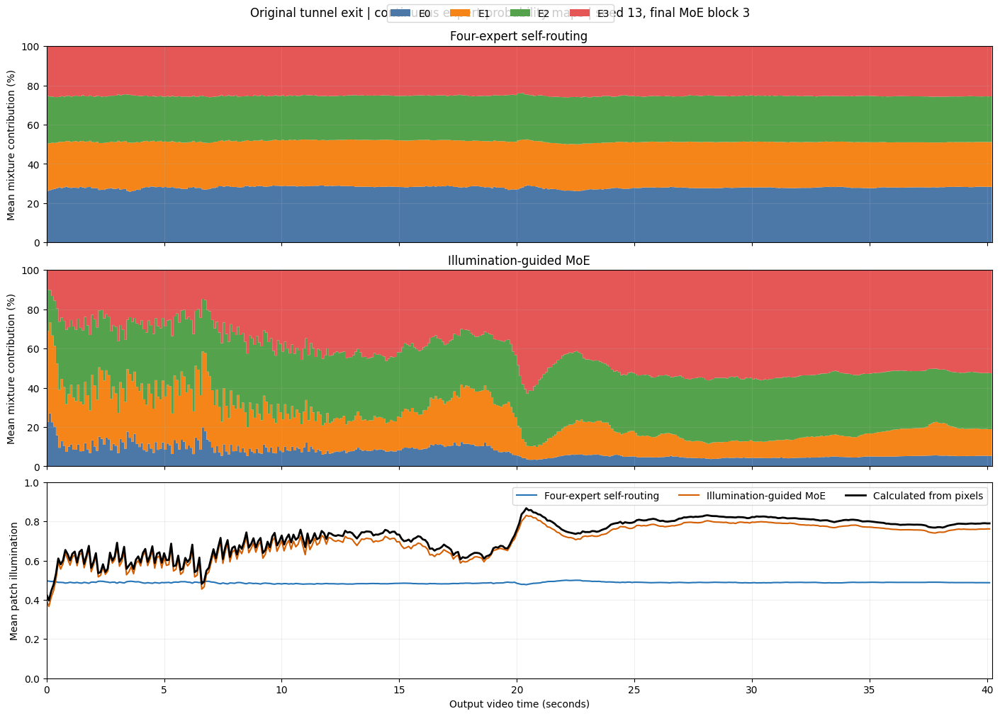

In [15]:
if export_comparison_videos:
    tunnel_source = dict(json.loads((repo_root / "outputs/bdd-illumination/selected_videos.json").read_text())[0])
    capture = cv2.VideoCapture(tunnel_source["path"])
    source_duration = capture.get(cv2.CAP_PROP_FRAME_COUNT) / capture.get(cv2.CAP_PROP_FPS)
    capture.release()
    tunnel_source["segment_seconds"] = (
        min(source_duration, tunnel_max_seconds) if tunnel_max_seconds is not None else source_duration
    )
    tunnel_source["start_seconds"] = 0.0
    tunnel_report = export_routing_video("tunnel_exit", [tunnel_source])
    show_video_with_areas(tunnel_report, "Original tunnel exit | continuous expert-probability maps")

### Matched highway / clear: day → dusk → night

Three real held-out BDD clips are concatenated, normally 15 seconds each. Cuts occur at 15 and
30 seconds. This is a matched-condition montage, not a claimed continuous day-to-night drive.
The area chart is placed immediately before its embedded video.

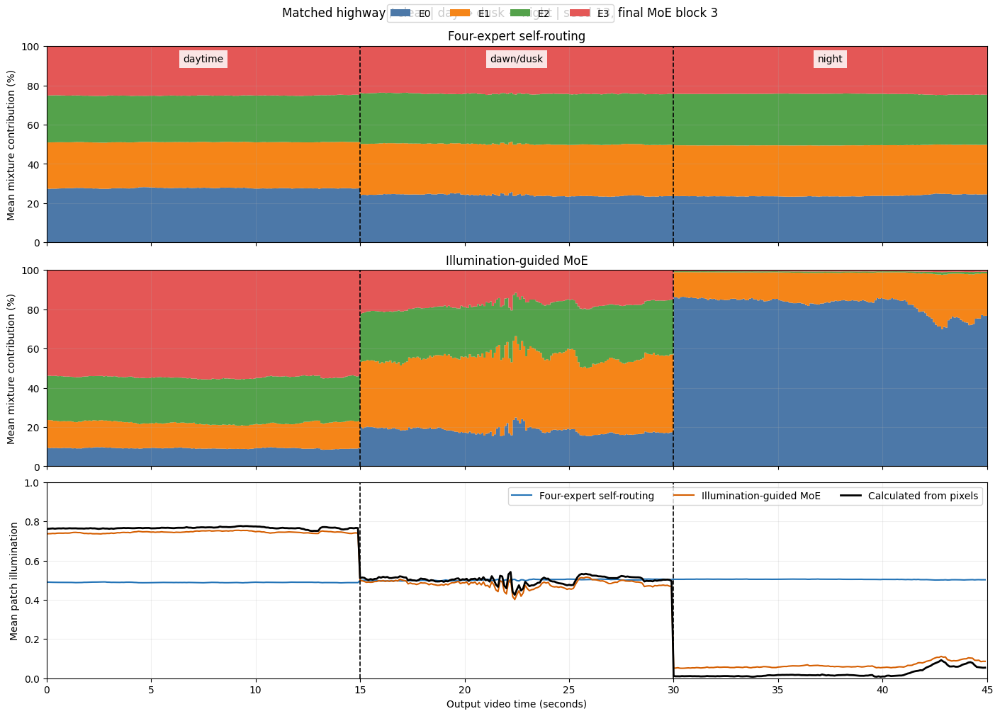

Completed illumination experiment. Figures, checkpoints, condition statistics and videos: C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-illumination-comparison\20261029T095722425903Z


In [16]:
if export_comparison_videos:
    combined_sources = json.loads((repo_root / "outputs/bdd-day-dusk-night/matched_sources.json").read_text())
    if [s["regime"] for s in combined_sources] != ["daytime", "dawn/dusk", "night"]:
        raise ValueError("Expected daytime → dawn/dusk → night source order.")
    if any(s["scene"] != "highway" or s["weather"] != "clear" for s in combined_sources):
        raise ValueError("Combined clips must use the same highway/clear condition.")
    for source in combined_sources:
        source["segment_seconds"] = video_seconds_per_regime
    combined_report = export_routing_video("day_dusk_night", combined_sources)
    show_video_with_areas(combined_report, "Matched highway / clear | day → dusk → night")
write_status(state="complete", completed_models=len(seeds) * len(arms))
print(f"Completed illumination experiment. Figures, checkpoints, condition statistics and videos: {run_dir}")

## Completed full-data run: measured results

Saved run `20261029T095722425903Z` trained **nine fresh models**, three arms × three seeds, using all 70,000
training stills for 3,282 updates / 210,000 image exposures per model. The same fixed 134-image
scene-probe support set and 605-image query set were used for every arm. The results below are
means across the three training seeds; the plotted points, error bars and paired intervals retain
the variation between seeds.

| Arm | Linear (%) | Frozen kNN (%) | Masked RGB MSE ↓ | RankMe |
|---|---:|---:|---:|---:|
| Dense | 34.82 | 36.64 | 0.02177 | 20.31 |
| Four-expert self-routing | 35.04 | 36.86 | 0.02168 | 20.20 |
| Illumination-guided MoE | 33.33 | 38.24 | 0.02156 | 23.63 |

Calculated-illumination prediction mean absolute error (MAE) on all unmasked query patches is
**0.2713** for self-routing and **0.0392** for
illumination guidance, on the normalized 0–1 scale. This evaluates agreement with the pixel-derived
proxy, not physical-light ground truth or scene accuracy. Use the expert-weight-versus-illumination
plots to inspect whether adjacent expert roles emerge. Better target fit and higher RankMe alone
do not establish a downstream performance improvement.

Paired illumination-guided minus self-routing differences:

| Metric | Mean difference | Paired 95% t interval |
|---|---:|---:|
| knn_accuracy | +1.37741 | [-2.50344, +5.25826] |
| linear_accuracy | -1.70799 | [-8.38368, +4.96770] |
| masked_rgb_mse | -0.00012 | [-0.00045, +0.00021] |
| rankme | +3.42044 | [+0.43154, +6.40934] |

Accuracy differences are percentage points; RGB and RankMe retain their original units. Intervals
describe only three training seeds on this reused query panel. Selecting a coefficient from these
results needs confirmation on an independent split. The Dense arm has fewer parameters and expert
compute; comparisons of the two MoEs use identical parameter counts and the same four-way mixing rule.

### Regression minimum, maximum and expert anchors

Both the calculated target and the router-derived prediction lie in **[0, 1]**. Calibration uses
the 5th/95th percentiles of log median patch luminance from **4,480,000 training patches**.
Values below/above those training bounds are clipped. Calibration stays fixed across support,
query and video frames; there is no per-image or per-video rescaling.

| Expert anchor | Normalized target | Corresponding median linear-light luminance |
|---|---:|---:|
| E0 | 0.0000 | 0.001475 |
| E1 | 0.3333 | 0.010774 |
| E2 | 0.6667 | 0.078684 |
| E3 | 1.0000 | 0.574638 |

These are relative image brightness levels, not lux or annotated time-of-day categories.
Intermediate targets interpolate between adjacent anchors. The illumination loss is calculated
from each actual augmented view before masking, and is applied only to its corresponding visible
spatial tokens. The masking-alignment and label-independence checks also cover training records
without any scene/time-of-day fields. The small-data CPU checkpoint/resume test reproduces final
weights exactly; the delivered figures and videos come from the completed full-data run.
